<a href="https://colab.research.google.com/github/valjeon/TP_Regresion_Softmax/blob/main/TP_mlp/TNG%2BMLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP - Clasificación multiclase de texto con un MLP
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Partir del pipeline del TP de regresión softmax (preprocesamiento configurable + TF-IDF) y reemplazar el modelo lineal por un **MLP** con capas ocultas.
- Buscar con **Optuna** la mejor combinación de preprocesamiento, optimizador, activación, cantidad de capas y unidades ocultas.
- Comparar el MLP con la regresión softmax del TP anterior (accuracy, cantidad de parámetros y tiempos).
- Analizar cómo afectan la cantidad de capas y de unidades al sobreajuste y al tiempo de entrenamiento.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.

## 0. Setup

In [1]:
!pip install -q mlflow optuna

Se instalan `mlflow` y `optuna` (en Colab no vienen preinstaladas; PyTorch sí).
* **MLflow** registra los parámetros, las métricas por época y el modelo entrenado de cada corrida.
* **Optuna** hace la búsqueda automática de hiperparámetros.

In [2]:
import re
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42

def set_seed(seed=SEED):
    """Fija todas las semillas. Se llama antes de crear cada modelo para que cada corrida sea reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/12 10:58:27 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /usr/local/lib/python3.13/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Usando dispositivo: cpu


Se importan las librerías necesarias.

Se define una semilla (`SEED`) y la función `set_seed`, que se vuelve a llamar antes de crear cada modelo. Así cada corrida (cada trial de Optuna, cada semilla de los análisis) arranca de una inicialización conocida y los resultados se pueden reproducir. También se define el dispositivo (GPU si hay, si no CPU).

In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...


[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...


[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

Se descargan todo los paquetes de información que son utilizados en la etapa de preprocesamiento:
- la lista de stopwords
- wordnet que se usa para lematización
- punkt que sirve para tokenizar

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


Se carga el dataset de los 20 Newsgroups dividido en una variable de `train` y otra de `test`. No se cargan los headers, footers y quotes porque dan información acerca de las clases. Lo que queremos es clasificar en base a las palabras del documento.

Se guardan los nombres de las clases en class_names.

## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens) #devuelve los tokens escritos en un solo string y no como vector

La función `preprocess_text`recibe el texto, `remove_stopwords` y `normalization`.

Primero guarda en cada posición del vector `tokens`, una palabra del texto que fue pasado a minúsculas con `lower`. Luego con `isAlpha` se conservan solo los tokens formados por caracteres alfabéticos y el resto se eliminan. De esta forma, nos deshacemos de números, signos y otros caracteres especiales que no son palabras.

Se usa la misma lógica para eliminar los stopwords si es que se pasó como parámetro de entrada. Después, según el tipo de normalización indicada en la entrada, hace stemming o lematización con cada unas de las palabras de `tokens`.

Por último, devuelve todos los tokens juntos en un solo string separados por un espacio.

In [6]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin


normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # TODO: crear un TfidfVectorizer con los parámetros recibidos y ajustarlo (fit) sobre train_texts,
    # después transformar train_texts y test_texts con ese mismo vectorizer.
    vectorizer = TfidfVectorizer(ngram_range= ngram_range, max_features= max_features, min_df= min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


La función `vectorize_data` recibe como entradas los dataset de train y de test, con qué n-gramas se quiere trabajar, el máximo de palabras con mayores frecuencias (max features) y el mínimo de frecuencia de aparición a lo largo de los documentos que tienen que tener las palabras (min df).


Se crea un `vectorizer` con las especificaciones recibidas.
Luego se le aplica al dataset de train con `fit_transform` que hace lo siguiente:
* Ve todos los documentos y arma un vocabulario.
* Calcula el IDF de cada palabra que muestra qué tan "rara" es a lo largo de todo el dataset.
* Toma el vocabulario y los valores de IDF para contar las frecuencias de las palabras (TF) en cada documento y calcular la matriz final de números.

Después se vectoriza el dataset de test pero con `transform`. Entonces, usa el vocabulario y los pesos IDF obtenidos con el dataset de train y arma la matriz.

Por último, devuelve `vectorizer` y las matrices de ambos dataset.


In [8]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])

Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


### Sobre la normalización de los vectores

`TfidfVectorizer` usa por defecto `norm='l2'`, así que cada fila ya sale con norma euclídea 1. En la versión anterior (igual que en el TP de softmax) había un hiperparámetro `norm_type` (`'l2'` / `'none'`) que aplicaba un `Normalizer(norm='l2')` después de vectorizar. Normalizar L2 un vector que ya tiene norma 1 no lo cambia, así que **las dos ramas eran idénticas** y cualquier diferencia entre ellas en Optuna era ruido. Saqué ese hiperparámetro de todas las búsquedas. La celda siguiente lo comprueba.

In [9]:
from sklearn.preprocessing import Normalizer

_norms = np.sqrt(_Xtr.multiply(_Xtr).sum(axis=1)).A1
print("Norma L2 de cada fila que devuelve TfidfVectorizer:", np.round(_norms, 6))
_Xtr_renorm = Normalizer(norm="l2").fit_transform(_Xtr)
print("Diferencia máxima tras aplicar Normalizer(l2) encima:", abs(_Xtr - _Xtr_renorm).max())

Norma L2 de cada fila que devuelve TfidfVectorizer: [1. 1. 1.]
Diferencia máxima tras aplicar Normalizer(l2) encima: 0.0


## 4. Modelo: MLP (con la regresión softmax como caso particular)

La regresión softmax del TP anterior es **una sola capa lineal** que mapea el vector TF-IDF a un logit por clase. El MLP agrega entre la entrada y esa capa de salida una o más **capas ocultas**, cada una seguida de una activación no lineal. Con 0 capas ocultas el modelo vuelve a ser exactamente la regresión softmax, así que uso la misma clase para los dos y los comparo con el mismo código.

Igual que antes, el modelo devuelve los logits sin aplicar softmax, porque `CrossEntropyLoss` ya incluye el `log_softmax`.

In [10]:
ACTIVATIONS = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "ELU": nn.ELU, "Sigmoid": nn.Sigmoid}

class SoftmaxRegression(nn.Module):
    """Con hidden_units_list vacío es la regresión softmax (una capa lineal).
    Con capas ocultas es un MLP: Linear -> activación por cada capa, y una Linear de salida."""
    def __init__(self, input_dim, num_classes, hidden_units_list=None, activation_name="ReLU"):
        super().__init__()
        hidden_units_list = list(hidden_units_list or [])
        layers, d = [], input_dim
        for units in hidden_units_list:
            layers += [nn.Linear(d, units), ACTIVATIONS[activation_name]()]
            d = units
        layers.append(nn.Linear(d, num_classes))
        self.net = nn.Sequential(*layers)
        self.hidden_units_list = hidden_units_list

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())

Cambié la implementación de la clase respecto de la versión anterior:
* Las capas se arman en un `nn.Sequential` (`Linear` → activación por cada capa oculta, y una `Linear` final), y se crea una activación nueva por capa.
* Se elimina el parámetro `num_layers`, que era redundante con el largo de `hidden_units_list`.
* Antes, si había capas pero `activation_layer` era `None`, el forward intentaba usar `self.linear`, que en ese caso no existía. Ahora no hay ese caso borde.
* `count_params` cuenta los parámetros entrenables, para comparar la complejidad de los modelos.

In [11]:
# Sanity check: la regresión softmax y dos MLPs
_dummy = torch.randn(4, 10000)
for _hidden in [[], [16], [128, 64]]:
    _m = SoftmaxRegression(input_dim=10000, num_classes=20, hidden_units_list=_hidden)
    _out = _m(_dummy)
    assert _out.shape == (4, 20), "Revisá SoftmaxRegression"
    print(f"capas ocultas={str(_hidden):10s} salida={tuple(_out.shape)}  parámetros={count_params(_m):,}")

capas ocultas=[]         salida=(4, 20)  parámetros=200,020
capas ocultas=[16]       salida=(4, 20)  parámetros=160,356
capas ocultas=[128, 64]  salida=(4, 20)  parámetros=1,289,684


Ya en este chequeo se ve algo importante para el análisis posterior: con 10000 features de entrada, casi todos los parámetros están en la **primera capa** (10000 × unidades). Un MLP de 1 capa de 16 unidades tiene ~160 mil parámetros, **menos** que la regresión softmax (10000 × 20 ≈ 200 mil). Que un modelo tenga capas ocultas no significa que tenga más capacidad: eso depende del tamaño de las capas.

## 5. Entrenamiento

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss, accuracy y tiempo por época a TensorBoard y MLflow.

In [12]:
%load_ext tensorboard


In [13]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None,
                        run_name="softmax", verbose=True, trial=None):
    """Entrena `epochs` épocas. Si val_loader es None no se evalúa nada (entrenamiento final:
    el test no se mira durante el entrenamiento). Guarda el tiempo de entrenamiento de cada época.
    Si se pasa un trial de Optuna, reporta la accuracy de validación por época para el pruning."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        _sync()
        t0 = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        _sync()
        # tiempo de entrenamiento de la época (forward + backward + step), sin evaluación ni logging
        epoch_time = time.perf_counter() - t0
        train_loss, train_acc = running_loss / total, correct / total

        val_loss, val_acc = float("nan"), float("nan")
        if val_loader is not None:
            model.eval()
            running_loss, correct, total = 0.0, 0, 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    logits = model(xb)
                    loss = criterion(logits, yb)
                    running_loss += loss.item() * xb.size(0)
                    correct += (logits.argmax(dim=1) == yb).sum().item()
                    total += xb.size(0)
            val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        if verbose:
            msg = f"[{run_name}] Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f}"
            if val_loader is not None:
                msg += f" - val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}"
            print(msg + f" - {epoch_time:.2f}s")

        if writer is not None:
            writer.add_scalar("loss/train", train_loss, epoch)
            writer.add_scalar("accuracy/train", train_acc, epoch)
            writer.add_scalar("time/epoch_s", epoch_time, epoch)
            if val_loader is not None:
                writer.add_scalar("loss/val", val_loss, epoch)
                writer.add_scalar("accuracy/val", val_acc, epoch)
        if mlflow.active_run() is not None:
            metrics = {"train_loss": train_loss, "train_acc": train_acc, "epoch_time_s": epoch_time}
            if val_loader is not None:
                metrics.update({"val_loss": val_loss, "val_acc": val_acc})
            mlflow.log_metrics(metrics, step=epoch)

        if trial is not None:
            trial.report(val_acc, epoch)
            trial.set_user_attr("last_val_acc", val_acc)
            trial.set_user_attr("epochs_run", epoch + 1)
            trial.set_user_attr("time_per_epoch_s", float(np.mean(history["epoch_time"])))
            if trial.should_prune():
                raise optuna.TrialPruned()

    return history

* `to_tensor_dataset` convierte la matriz TF-IDF y las etiquetas en tensores para los `DataLoader`s.
* `train_softmax_model` entrena el modelo por la cantidad de `epochs` que recibe y, si se le pasa un `val_loader`, lo evalúa al final de cada época. Si `val_loader` es `None` no evalúa: así se usa en el entrenamiento final, para no mirar el test durante el entrenamiento.
* En `history` se guardan, por época, la loss y la accuracy de train y validación y **el tiempo de entrenamiento de la época**, medido en el código con `time.perf_counter` (solo forward + backward + step, sin evaluación ni logging). En la versión anterior usaba la duración de los runs de MLflow, que incluye logging y serialización del modelo y no está normalizada por época.
* Si recibe un `trial` de Optuna, reporta la accuracy de validación de cada época para que el pruner pueda cortar los trials que vienen mal.

Funciones auxiliares que uso en el resto del notebook:
* `make_loaders` arma los `DataLoader`s con un generador con semilla (orden de batches reproducible).
* `make_optimizer` crea Adam, RMSprop o SGD.
* `summarize_history` resume una corrida: máximo de accuracy de validación y su época, primera época con el 99% de ese máximo (medida de **convergencia**), época de mínima loss de validación (a partir de ahí la validación empieza a empeorar: **punto de divergencia**), brecha train − validación al final, y tiempos.
* `run_config` vectoriza una configuración y la entrena con varias semillas sobre la partición train/validación.
* `plot_mean_std` y `summary_table` grafican y resumen la media ± desvío entre semillas.

In [14]:
def make_loaders(train_ds, val_ds, batch_size, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g)
    val_loader = None if val_ds is None else DataLoader(val_ds, batch_size=512, shuffle=False)
    return train_loader, val_loader


def make_optimizer(name, params, lr, momentum=0.0):
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    if name == "RMSprop":
        return optim.RMSprop(params, lr=lr, momentum=momentum)
    return optim.SGD(params, lr=lr, momentum=momentum)


def summarize_history(h):
    va, vl = np.array(h["val_acc"]), np.array(h["val_loss"])
    t = np.array(h["epoch_time"])
    epoch_peak = int(va.argmax()) + 1
    epoch_99 = int(np.argmax(va >= 0.99 * va.max())) + 1
    return {
        "peak_val_acc": va.max(), "epoch_peak": epoch_peak, "final_val_acc": va[-1],
        "final_train_acc": h["train_acc"][-1], "gap_final": h["train_acc"][-1] - va[-1],
        "epoch_min_val_loss": int(vl.argmin()) + 1, "epoch_99": epoch_99,
        "time_per_epoch_s": t.mean(), "time_total_s": t.sum(), "time_to_99_s": t[:epoch_99].sum(),
    }


def run_config(remove_stopwords, normalization, ngram_range, max_features, min_df, optimizer_name, lr,
               momentum, batch_size, hidden_units, activation, epochs, seeds, tag, experiment_type, verbose=False):
    """Entrena una configuración con varias semillas sobre train/validación.
    Devuelve (histories, cantidad de parámetros)."""
    tr_texts, val_texts = get_split_texts(remove_stopwords, normalization)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range, max_features, min_df)
    train_ds, val_ds = to_tensor_dataset(X_tr, y_tr), to_tensor_dataset(X_val, y_val)
    histories = []
    for seed in seeds:
        set_seed(seed)
        train_loader, val_loader = make_loaders(train_ds, val_ds, batch_size, seed)
        model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES, hidden_units, activation)
        n_params = count_params(model)
        opt = make_optimizer(optimizer_name, model.parameters(), lr, momentum)
        writer = SummaryWriter(log_dir=f"runs/{tag}_seed{seed}")
        with mlflow.start_run(run_name=f"{tag}_seed{seed}"):
            mlflow.log_params({
                "remove_stopwords": remove_stopwords, "normalization": normalization,
                "ngram_range": str(ngram_range), "max_features": max_features, "min_df": min_df,
                "optimizer_name": optimizer_name, "lr": lr, "momentum": momentum, "batch_size": batch_size,
                "hidden_units": str(hidden_units), "activation": activation, "n_params": n_params,
                "epochs": epochs, "seed": seed, "experiment_type": experiment_type,
            })
            h = train_softmax_model(model, train_loader, val_loader, opt, epochs, writer=writer,
                                    run_name=f"{tag}_s{seed}", verbose=verbose)
            mlflow.log_metrics({k: float(v) for k, v in summarize_history(h).items()})
        writer.close()
        histories.append(h)
    return histories, n_params


def plot_mean_std(ax, histories, key, label=None, **kw):
    arr = np.array([h[key] for h in histories])
    x = np.arange(1, arr.shape[1] + 1)
    m, s = arr.mean(axis=0), arr.std(axis=0)
    line, = ax.plot(x, m, label=label, **kw)
    ax.fill_between(x, m - s, m + s, alpha=0.2, color=line.get_color())
    return line


def summary_table(groups, n_params=None,
                  cols=("peak_val_acc", "epoch_peak", "final_val_acc", "gap_final", "epoch_min_val_loss",
                        "time_per_epoch_s", "time_to_99_s")):
    """groups: dict etiqueta -> lista de histories (una por semilla). Devuelve media ± desvío por etiqueta."""
    rows = []
    for label, hs in groups.items():
        df = pd.DataFrame([summarize_history(h) for h in hs])
        row = {"config": label, "n_seeds": len(hs)}
        if n_params is not None:
            row["n_params"] = f"{n_params[label]:,}"
        for col in cols:
            fmt = "{:.4f} ± {:.4f}" if ("acc" in col or "gap" in col) else "{:.2f} ± {:.2f}"
            row[col] = fmt.format(df[col].mean(), df[col].std(ddof=0))
        rows.append(row)
    return pd.DataFrame(rows)

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`), **de entrenamiento** (optimizador, `lr`, `momentum`, `batch_size`) y **de arquitectura** (cantidad de capas ocultas, unidades por capa y activación), todos en un mismo `objective`.

**Optimización de tiempo**: el preprocesamiento (tokenización + stopwords + normalización) solo depende de `remove_stopwords` y `normalization`, así que lo precalculamos una sola vez para las 6 combinaciones y lo cacheamos.

In [15]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...


  listo: (False, 'none')


  listo: (False, 'stem')


  listo: (False, 'lemmatize')


  listo: (True, 'none')


  listo: (True, 'stem')


  listo: (True, 'lemmatize')


**Partición de validación fija.** Separo una sola vez un 20% estratificado del train como validación. Se usa para la búsqueda y para todos los análisis. El test set original se usa **una sola vez**, en la evaluación final.

In [16]:
idx_tr, idx_val = train_test_split(
    np.arange(len(newsgroups_train.data)), test_size=0.2, random_state=SEED,
    stratify=newsgroups_train.target,
)
y_tr, y_val = newsgroups_train.target[idx_tr], newsgroups_train.target[idx_val]

def get_split_texts(remove_stopwords, normalization):
    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    return [train_texts[i] for i in idx_tr], [train_texts[i] for i in idx_val]

print(f"Train: {len(idx_tr)} | Validación: {len(idx_val)} | Test (solo para la evaluación final): {len(newsgroups_test.data)}")

Train: 9051 | Validación: 2263 | Test (solo para la evaluación final): 7532


**Cambios en el espacio de búsqueda respecto de la versión anterior**

* **Sin `norm_type`** (ver sección 3).
* **Un rango de `lr` por optimizador.** Antes los tres optimizadores compartían el rango `1e-3`-`1e-1`. Para SGD eso no sirve: los trials con SGD terminaban con loss ≈ 3.0 ≈ ln(20) y accuracy ≈ 0.05, que es lo mismo que predecir al azar entre 20 clases, y el pruner los cortaba sin que yo lo comentara. Los gradientes respecto de cada peso son chicos (los vectores TF-IDF tienen norma 1 repartida en miles de dimensiones), y Adam/RMSprop lo compensan normalizando el paso, pero SGD no. En una prueba aparte, un MLP de una capa con ReLU y SGD solo aprende en 5 épocas con `lr` de ~0.3 a ~3 (con 0.1 casi no se mueve y con 5 diverge).
* **Rango de unidades más amplio:** de 16 a 1024 (antes 16-256), para que la búsqueda pueda explorar modelos con bastante más capacidad que la regresión softmax. El mismo rango se usa en la búsqueda de sobreajuste de la sección 10.
* **Sin `adam_beta1/2` ni `rmsprop_alpha`.** Con 40 trials, cada dimensión extra hace la búsqueda menos eficiente, y esos parámetros suelen importar mucho menos que el `lr`. Uso los valores por defecto.
* **40 trials en vez de 15** y **sampler con semilla**, para que la búsqueda sea reproducible.
* El pruner (`MedianPruner`) se mantiene. Corta un trial cuando, a partir de la 2ª época, su accuracy de validación queda por debajo de la mediana de los trials anteriores en la misma época. En la sección 6.1 analizo qué trials cortó y por qué.

In [17]:
N_TRIALS = 40
EPOCHS_SEARCH = 5
LR_RANGES = {"Adam": (1e-4, 1e-1), "RMSprop": (1e-4, 1e-1), "SGD": (1e-2, 1e1)}
UNITS_CHOICES = [16, 32, 64, 128, 256, 512, 1024]

def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    optimizer_name = trial.suggest_categorical("optimizer_name", ["Adam", "RMSprop", "SGD"])
    lr = trial.suggest_float(f"lr_{optimizer_name.lower()}", *LR_RANGES[optimizer_name], log=True)
    momentum = trial.suggest_float(f"momentum_{optimizer_name.lower()}", 0.0, 0.95) if optimizer_name != "Adam" else 0.0
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    num_layers = trial.suggest_int("num_layers", 1, 3)
    hidden_units = [trial.suggest_categorical(f"units_layer_{i}", UNITS_CHOICES) for i in range(num_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))

    tr_texts, val_texts = get_split_texts(remove_stopwords, normalization)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)

    set_seed(SEED)
    train_loader, val_loader = make_loaders(to_tensor_dataset(X_tr, y_tr), to_tensor_dataset(X_val, y_val), batch_size)
    model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES, hidden_units, activation)
    optimizer = make_optimizer(optimizer_name, model.parameters(), lr, momentum)
    trial.set_user_attr("n_params", count_params(model))
    trial.set_user_attr("hidden_units", str(hidden_units))

    status = "ok"
    try:
        with mlflow.start_run(run_name=f"optuna_trial_{trial.number}"):
            mlflow.log_params({**trial.params, "epochs": EPOCHS_SEARCH, "experiment_type": "optuna"})
            history = train_softmax_model(model, train_loader, val_loader, optimizer,
                                          epochs=EPOCHS_SEARCH, verbose=False, trial=trial)
        trial.set_user_attr("final_train_acc", history["train_acc"][-1])
        trial.set_user_attr("final_train_loss", history["train_loss"][-1])
        return history["val_acc"][-1]
    except optuna.TrialPruned:
        status = "podado"
        raise
    finally:
        print(f"trial {trial.number:2d} | {optimizer_name:7s} lr={lr:.3g} | {activation:7s} {str(hidden_units):18s} "
              f"| val_acc={trial.user_attrs.get('last_val_acc', float('nan')):.4f} "
              f"(época {trial.user_attrs.get('epochs_run', 0)}) | {status}")


mlflow.set_experiment("mlp_20newsgroups")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
study.optimize(objective, n_trials=N_TRIALS)

print("\nMejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", round(study.best_value, 4))

2026/11/12 11:01:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/12 11:01:58 INFO mlflow.store.db.utils: Updating database tables


2026/11/12 11:01:59 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


trial  0 | Adam    lr=0.000818 | ReLU    [256, 1024]        | val_acc=0.5952 (época 5) | ok


trial  1 | Adam    lr=0.0583 | ELU     [64]               | val_acc=0.6217 (época 5) | ok


trial  2 | SGD     lr=0.818 | Tanh    [32, 256, 512]     | val_acc=0.0530 (época 5) | ok


... (33 outputs left out)

trial 36 | Adam    lr=0.00261 | Tanh    [512]              | val_acc=0.7225 (época 5) | ok


trial 37 | RMSprop lr=0.0252 | Tanh    [512]              | val_acc=0.6346 (época 2) | podado


trial 38 | Adam    lr=0.00182 | Tanh    [512]              | val_acc=0.6416 (época 2) | podado


trial 39 | Adam    lr=0.000528 | Tanh    [512]              | val_acc=0.7419 (época 5) | ok

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 2, 'optimizer_name': 'Adam', 'lr_adam': 0.0005278295130865957, 'batch_size': 128, 'num_layers': 1, 'units_layer_0': 512, 'activation': 'Tanh'}
Mejor accuracy de validación: 0.7419


`objective`
1. Se eligen con `trial.suggest_*` los hiperparámetros de preprocesamiento, el optimizador con su propio rango de `lr` (y `momentum` para SGD y RMSprop), el `batch_size`, la cantidad de capas ocultas (1 a 3), las unidades de cada capa y la activación.
2. Se toma el texto preprocesado del cache, se separa con la partición fija de train/validación y se vectoriza.
3. Se fija la semilla, se crea el modelo y se entrena 5 épocas reportando la accuracy de validación de cada época al pruner.
4. Cada trial queda registrado en MLflow, y en `user_attrs` se guardan la cantidad de parámetros, la arquitectura, el tiempo por época y la última accuracy de validación (también la de los trials podados).

**Optuna Study**: sampler TPE con semilla, `MedianPruner` (no poda durante los primeros 5 trials ni en la 1ª época) y 40 trials.

## 6.1. Análisis de los trials de Optuna

In [18]:
rows = []
for t in study.trials:
    p = t.params
    opt_name = p["optimizer_name"]
    rows.append({
        "number": t.number, "state": "completo" if t.state == optuna.trial.TrialState.COMPLETE else "podado",
        "val_acc": t.user_attrs.get("last_val_acc"), "epochs_run": t.user_attrs.get("epochs_run"),
        "optimizer": opt_name, "lr": p[f"lr_{opt_name.lower()}"], "activation": p["activation"],
        "hidden_units": t.user_attrs["hidden_units"], "num_layers": p["num_layers"],
        "n_params": t.user_attrs["n_params"], "batch_size": p["batch_size"],
        "remove_stopwords": p["remove_stopwords"], "normalization": p["normalization"],
        "ngram_range": p["ngram_range"], "max_features": p["max_features"], "min_df": p["min_df"],
        "final_train_acc": t.user_attrs.get("final_train_acc"),
        "time_per_epoch_s": t.user_attrs.get("time_per_epoch_s"),
    })
df_trials = pd.DataFrame(rows)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
display(df_trials.sort_values("val_acc", ascending=False).reset_index(drop=True).round(4))

,number,state,val_acc,epochs_run,optimizer,lr,activation,hidden_units,num_layers,n_params,batch_size,remove_stopwords,normalization,ngram_range,max_features,min_df,final_train_acc,time_per_epoch_s
0,39,completo,0.7419,5,Adam,0.0005,Tanh,[512],1,5130772,128,True,stem,1_2gram,10000,2,0.9074,1.7359
1,36,completo,0.7225,5,Adam,0.0026,Tanh,[512],1,5130772,64,True,stem,1_2gram,10000,2,0.9720,2.3897
2,35,completo,0.7216,5,Adam,0.0028,Tanh,[512],1,5130772,64,True,stem,1_2gram,10000,2,0.9718,2.5316
3,33,completo,0.7212,5,Adam,0.0026,Tanh,[512],1,5130772,128,True,lemmatize,1_2gram,10000,2,0.9722,1.7632
4,16,completo,0.7101,5,RMSprop,0.0001,ReLU,[512],1,5130772,64,True,lemmatize,1_2gram,10000,1,0.7979,2.3394
5,12,completo,0.7075,5,Adam,0.0074,ReLU,[512],1,2570772,128,True,stem,1gram,5000,5,0.9713,0.8266
6,26,completo,0.7057,5,RMSprop,0.0105,ReLU,[1024],1,10261524,32,True,none,1_2gram,10000,1,0.9717,16.0509
7,9,completo,0.7057,5,Adam,0.0112,ReLU,[512],1,5130772,128,True,lemmatize,1_2gram,10000,1,0.9709,1.8537
8,31,completo,0.7048,5,RMSprop,0.0134,ReLU,[1024],1,10261524,32,True,none,1_2gram,10000,1,0.9712,16.5910
9,13,completo,0.7048,5,Adam,0.0065,ReLU,[1024],1,5141524,128,True,stem,1gram,5000,2,0.9705,1.5523


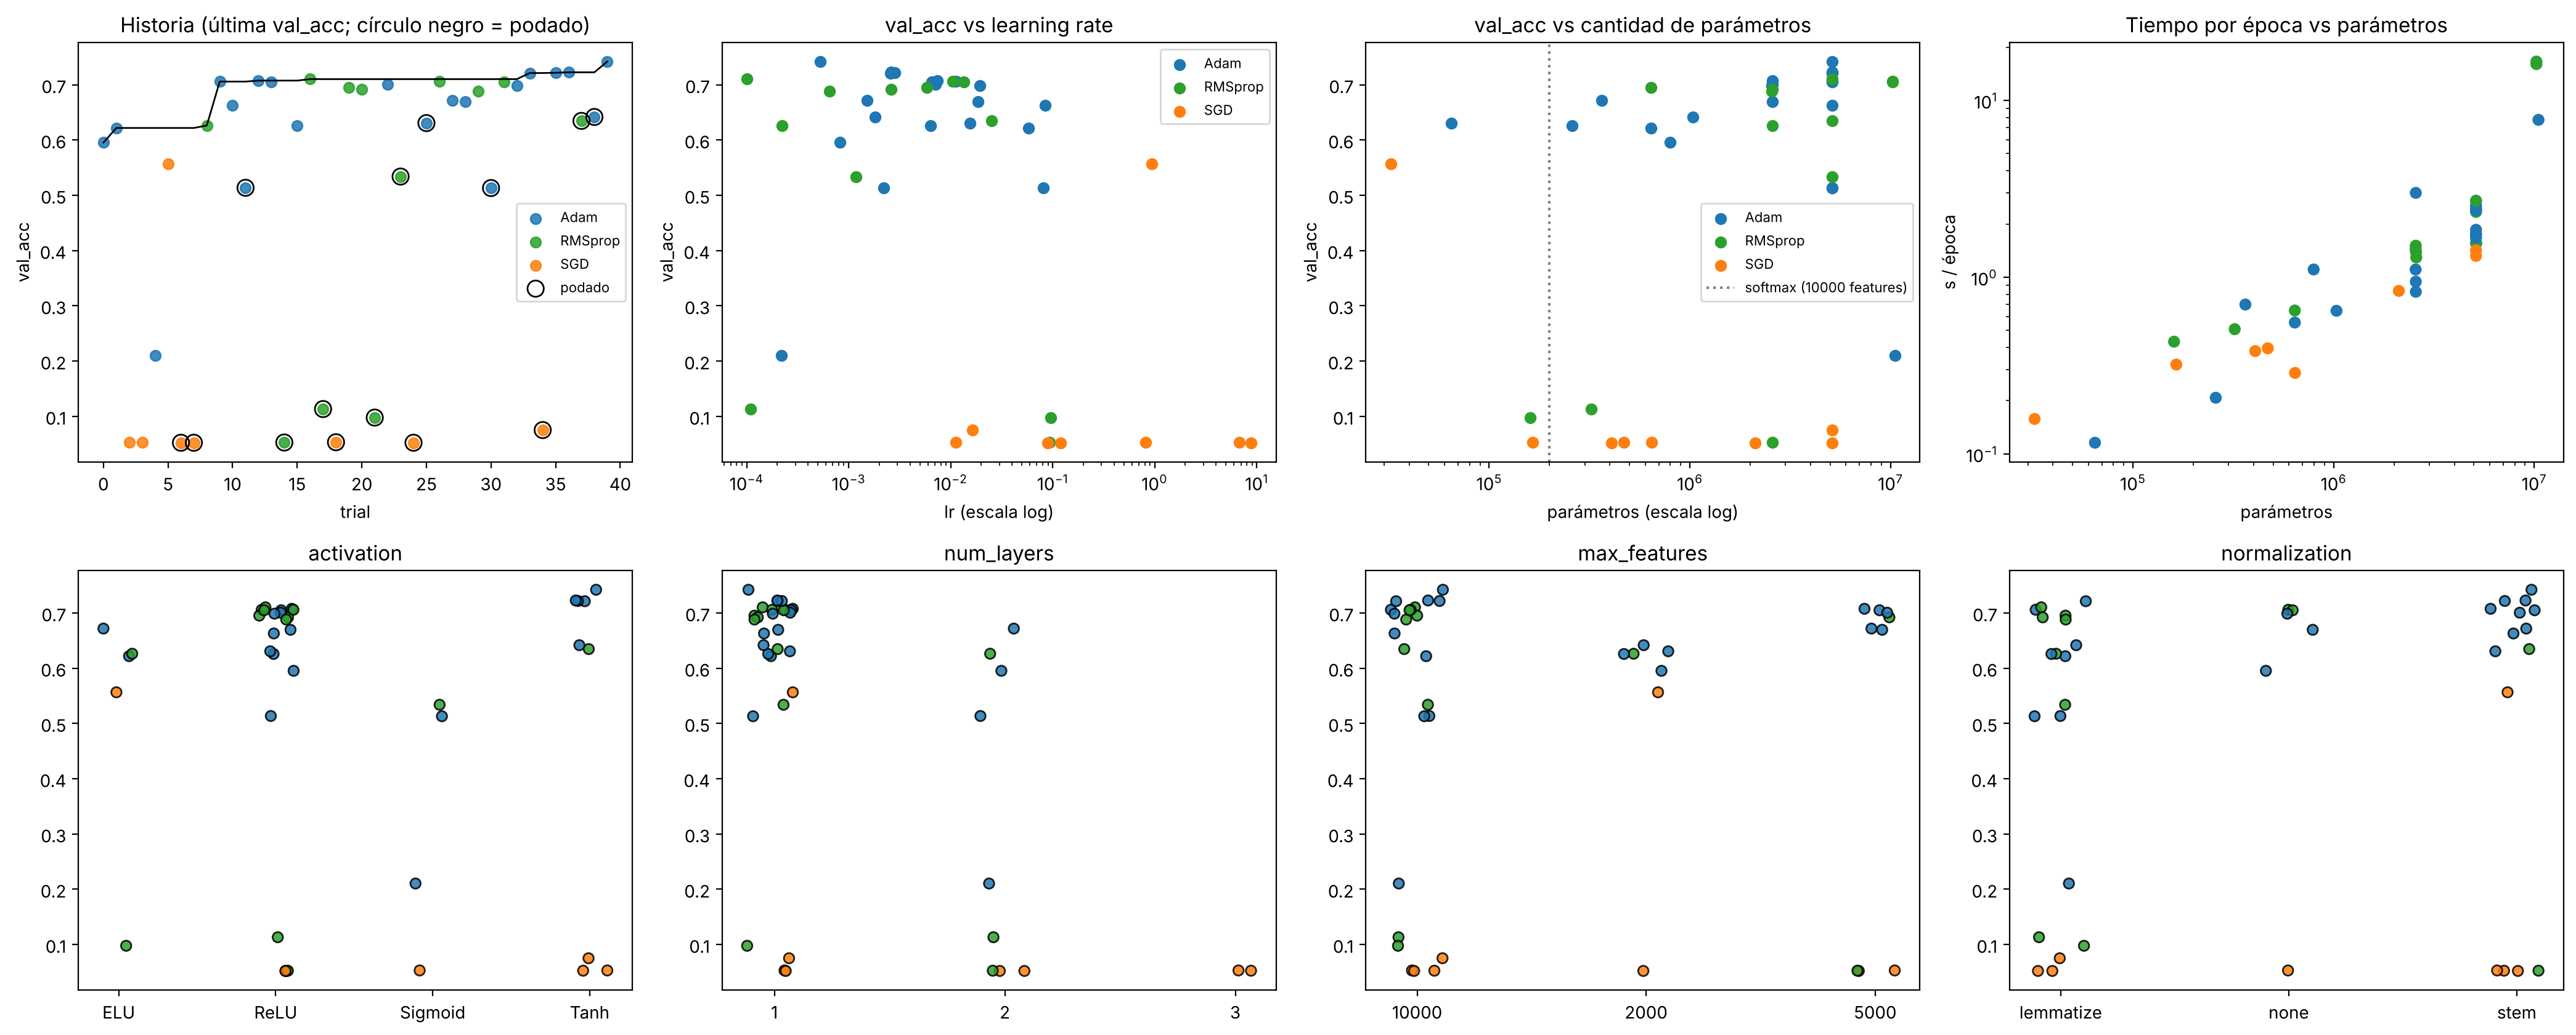

In [19]:
colors = {"Adam": "tab:blue", "RMSprop": "tab:green", "SGD": "tab:orange"}
rng = np.random.default_rng(SEED)
completed = df_trials["state"] == "completo"

fig, axes = plt.subplots(2, 4, figsize=(21, 8.5))
axes = axes.ravel()

ax = axes[0]
for opt_name, g in df_trials.groupby("optimizer"):
    ax.scatter(g["number"], g["val_acc"], color=colors[opt_name], label=opt_name,
               marker="o", alpha=0.85)
pruned = df_trials[~completed]
ax.scatter(pruned["number"], pruned["val_acc"], facecolors="none", edgecolors="k", s=90, label="podado")
ax.plot(df_trials["number"], df_trials["val_acc"].where(completed).cummax().ffill(), color="k", lw=1)
ax.set_xlabel("trial"); ax.set_title("Historia (última val_acc; círculo negro = podado)"); ax.legend(fontsize=8)

ax = axes[1]
for opt_name, g in df_trials.groupby("optimizer"):
    ax.scatter(g["lr"], g["val_acc"], color=colors[opt_name], label=opt_name)
ax.set_xscale("log"); ax.set_xlabel("lr (escala log)"); ax.set_title("val_acc vs learning rate"); ax.legend(fontsize=8)

ax = axes[2]
for opt_name, g in df_trials.groupby("optimizer"):
    ax.scatter(g["n_params"], g["val_acc"], color=colors[opt_name], label=opt_name)
ax.set_xscale("log"); ax.set_xlabel("parámetros (escala log)"); ax.set_title("val_acc vs cantidad de parámetros")
ax.axvline(10000 * 20, color="gray", ls=":", label="softmax (10000 features)"); ax.legend(fontsize=8)

ax = axes[3]
ax.scatter(df_trials["n_params"], df_trials["time_per_epoch_s"], c=[colors[o] for o in df_trials["optimizer"]])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("parámetros"); ax.set_ylabel("s / época")
ax.set_title("Tiempo por época vs parámetros")

for ax, p in zip(axes[4:], ["activation", "num_layers", "max_features", "normalization"]):
    levels = sorted(df_trials[p].unique(), key=str)
    for k, lev in enumerate(levels):
        g = df_trials[df_trials[p] == lev]
        x = k + rng.uniform(-0.12, 0.12, len(g))
        ax.scatter(x, g["val_acc"], c=[colors[o] for o in g["optimizer"]], alpha=0.85,
                   edgecolors=["k" if s == "podado" else "none" for s in g["state"]])
    ax.set_xticks(range(len(levels))); ax.set_xticklabels([str(l) for l in levels]); ax.set_title(p)
for ax in axes[:3]:
    ax.set_ylabel("val_acc")
plt.tight_layout(); plt.show()

Por optimizador:


,trials,podados,val_acc_media,val_acc_max
optimizer,,,,
Adam,20,4,0.6390,0.7419
RMSprop,12,5,0.5211,0.7101
SGD,8,5,0.1183,0.5563


Por activación:


,trials,podados,val_acc_media,val_acc_max
activation,,,,
ELU,5,1,0.5147,0.6717
ReLU,22,7,0.5333,0.7101
Sigmoid,4,3,0.3276,0.5338
Tanh,9,3,0.4849,0.7419


Por optimizador y activación (media de val_acc, cantidad de trials entre paréntesis):


activation,ELU,ReLU,Sigmoid,Tanh
optimizer,,,,
Adam,0.647 (2),0.656 (11),0.362 (2),0.71 (5)
RMSprop,0.362 (2),0.545 (8),0.534 (1),0.635 (1)
SGD,0.556 (1),0.052 (3),0.053 (1),0.06 (3)


Por cantidad de capas ocultas (solo trials completos):


,trials,val_acc_media,val_acc_max,params_mediana
num_layers,,,,
1,20,0.6878,0.7419,3850772.0
2,4,0.5259,0.6717,1690004.0
3,2,0.0528,0.0530,317460.0


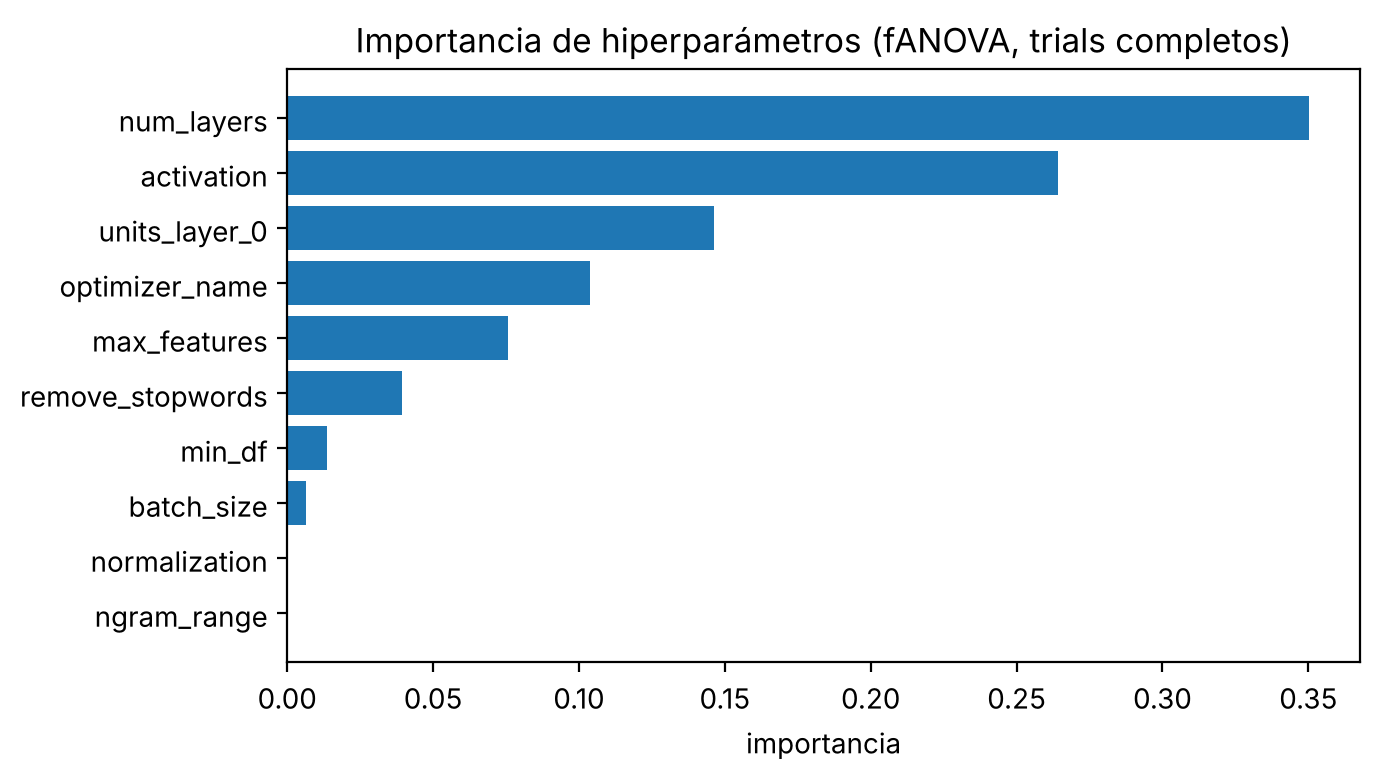

In [20]:
print("Por optimizador:")
display(df_trials.groupby("optimizer").agg(trials=("number", "count"), podados=("state", lambda s: (s == "podado").sum()),
                                            val_acc_media=("val_acc", "mean"), val_acc_max=("val_acc", "max")).round(4))
print("Por activación:")
display(df_trials.groupby("activation").agg(trials=("number", "count"), podados=("state", lambda s: (s == "podado").sum()),
                                             val_acc_media=("val_acc", "mean"), val_acc_max=("val_acc", "max")).round(4))
print("Por optimizador y activación (media de val_acc, cantidad de trials entre paréntesis):")
g = df_trials.groupby(["optimizer", "activation"])["val_acc"]
display((g.mean().round(3).astype(str) + " (" + g.count().astype(str) + ")").unstack(fill_value="-"))
print("Por cantidad de capas ocultas (solo trials completos):")
display(df_trials[completed].groupby("num_layers").agg(trials=("number", "count"), val_acc_media=("val_acc", "mean"),
                                                        val_acc_max=("val_acc", "max"), params_mediana=("n_params", "median")).round(4))

try:
    evaluator = optuna.importance.FanovaImportanceEvaluator(seed=SEED)
    imp = optuna.importance.get_param_importances(study, evaluator=evaluator)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(list(imp.keys())[::-1], list(imp.values())[::-1])
    ax.set_title("Importancia de hiperparámetros (fANOVA, trials completos)"); ax.set_xlabel("importancia")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("No se pudo calcular la importancia:", e)

**Qué muestran los 40 trials**

* **Optimizador.** Adam es el más robusto: 20 trials, media de 0.639 y máximo de 0.742. Le sigue RMSprop (0.521 de media, 0.710 de máximo). SGD casi nunca aprende: 7 de sus 8 trials quedan en ~0.05 de accuracy, es decir, en predicción al azar entre 20 clases. Dentro de su rango, los `lr` ≲ 0.1 son demasiado chicos (los podó el pruner en la época 2), los `lr` ≳ 5 divergen, y los que quedan en el medio (0.8 con 3 capas Tanh) tampoco arrancan en 5 épocas. El único que aprende es una red chica de 1 capa con ELU y `lr` ≈ 0.94 (0.556). En el MLP la ventana de `lr` útil de SGD es angosta y depende de la arquitectura, mientras que Adam y RMSprop ajustan el paso por parámetro.
* **Sigmoid.** De sus 4 trials, 3 fueron podados en la época 2 y el otro (Adam con `lr` = 2e-4, dos capas grandes) llegó a 0.21. Los trials podados no estaban rotos: tenían 0.51-0.53 en la época 2, aprendiendo, pero más lento que la mediana. La sigmoide tiene derivada ≤ 0.25 y salidas no centradas en cero, lo que achica los gradientes que llegan a la primera capa y hace más lento el arranque, sobre todo al apilar capas. En una prueba aparte, un MLP de 1 capa sigmoide con Adam llega a ~0.73 en 5 épocas, así que la sigmoide funciona con el optimizador adecuado. El pruner, al comparar en la época 2, **favorece a las configuraciones que arrancan rápido**, y eso pesa en contra de la sigmoide.
* **Cantidad de capas.** El mejor resultado con 1 capa es 0.742; con 2, 0.672; con 3, 0.053. Pero los dos únicos trials con 3 capas usaron SGD, así que en esta búsqueda **la cantidad de capas está mezclada con el optimizador**. La importancia alta de `num_layers` en fANOVA se debe en gran parte a eso. El efecto de la profundidad lo mido de forma controlada en la sección 9.2.
* **Unidades.** Los mejores trials tienen una capa de 256 a 1024 unidades, es decir, entre 2.5 y 10 millones de parámetros, bastante más que la regresión softmax (200 mil).
* **Preprocesamiento.** Los mejores trials coinciden con el TP anterior en stopwords quitadas y stemming o lematización, con 10000 términos. Esta vez el ganador usa unigramas + bigramas con `min_df` = 2.
* **La búsqueda todavía estaba mejorando.** El mejor trial es el último (39). Los últimos 7 trials exploran la misma zona (1 capa de 512 con Tanh) y, sin contar el único con SGD, van de 0.634 a 0.742 según el optimizador, el `lr` y el `batch_size`. Con 40 trials, el resultado es una buena configuración, no una garantía de óptimo, y varios trials quedan a menos de 1-2 puntos entre sí.

### Mejores hiperparámetros

In [21]:
best = study.best_params
BEST_OPTIMIZER_NAME = best["optimizer_name"]
BEST_HIDDEN_UNITS = [best[f"units_layer_{i}"] for i in range(best["num_layers"])]
BEST_CFG = dict(
    remove_stopwords=best["remove_stopwords"], normalization=best["normalization"],
    ngram_range=(1, 1) if best["ngram_range"] == "1gram" else (1, 2),
    max_features=best["max_features"], min_df=best["min_df"],
    optimizer_name=BEST_OPTIMIZER_NAME, lr=best[f"lr_{BEST_OPTIMIZER_NAME.lower()}"],
    momentum=best.get(f"momentum_{BEST_OPTIMIZER_NAME.lower()}", 0.0),
    batch_size=best["batch_size"], hidden_units=BEST_HIDDEN_UNITS, activation=best["activation"],
)

# Mejor configuración de la regresión softmax del TP anterior (misma partición de validación, misma búsqueda)
SOFTMAX_CFG = dict(remove_stopwords=True, normalization="stem", ngram_range=(1, 1), max_features=10000, min_df=1,
                   optimizer_name="Adam", lr=0.013275371418594568, momentum=0.0, batch_size=128,
                   hidden_units=[], activation="ReLU")
SEEDS = [SEED, SEED + 1, SEED + 2]

print("MLP (mejor de Optuna):")
for k, v in BEST_CFG.items():
    print(f"  {k:18s} {v}")
print("\nRegresión softmax (mejor del TP anterior):", SOFTMAX_CFG)

MLP (mejor de Optuna):
  remove_stopwords   True
  normalization      stem
  ngram_range        (1, 2)
  max_features       10000
  min_df             2
  optimizer_name     Adam
  lr                 0.0005278295130865957
  momentum           0.0
  batch_size         128
  hidden_units       [512]
  activation         Tanh

Regresión softmax (mejor del TP anterior): {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': (1, 1), 'max_features': 10000, 'min_df': 1, 'optimizer_name': 'Adam', 'lr': 0.013275371418594568, 'momentum': 0.0, 'batch_size': 128, 'hidden_units': [], 'activation': 'ReLU'}


## 6.2. Dinámica de entrenamiento y elección de la cantidad de épocas

La búsqueda evalúa cada configuración con 5 épocas, y en la versión anterior el modelo final se entrenaba 20 sin justificarlo. Antes de entrenar el modelo final, entreno la mejor configuración 30 épocas sobre train/validación con 3 semillas y elijo la cantidad de épocas **con validación** (la de mayor accuracy media).

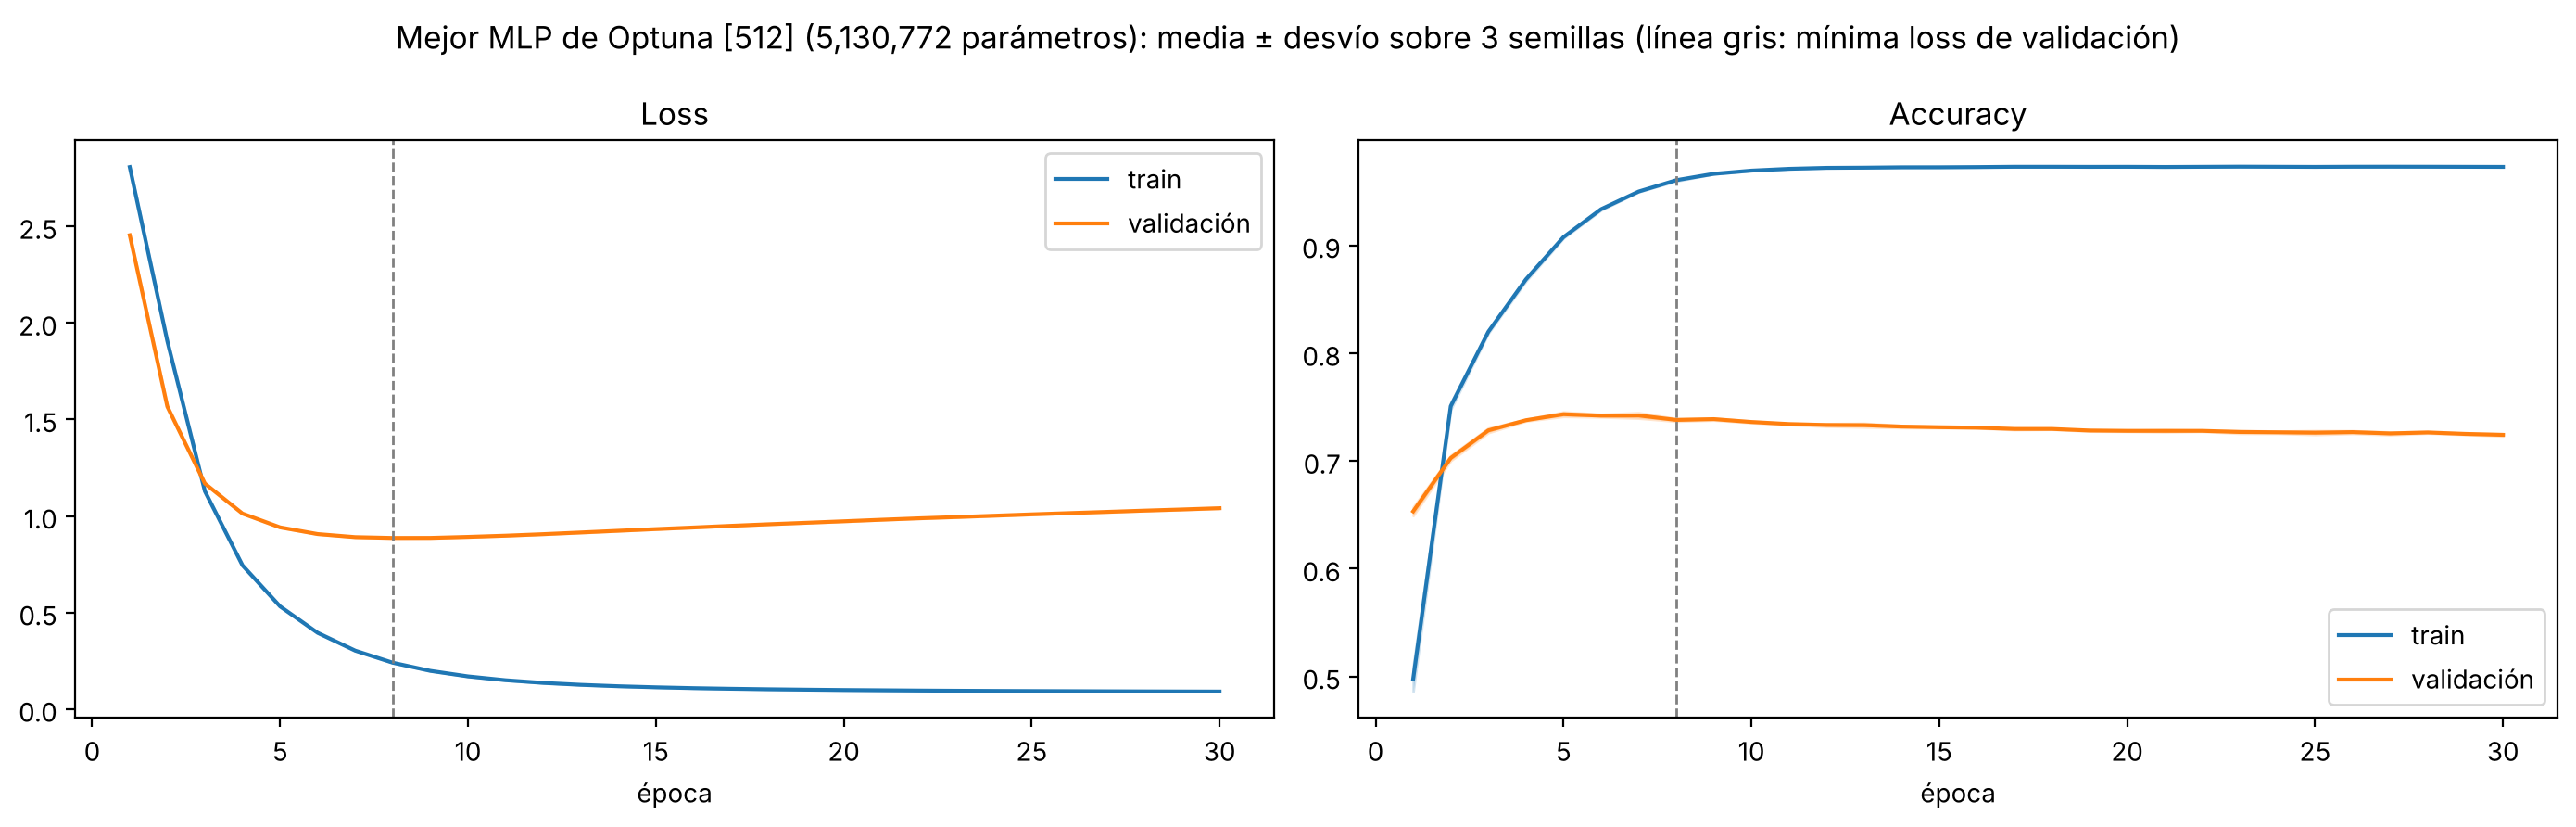

Época con mayor val_acc media: 5 (val_acc = 0.7434)
Época con menor val_loss media: 8
val_acc media en la época 5 (la que usa la búsqueda): 0.7434 | en la época 30: 0.7243


,config,n_seeds,n_params,peak_val_acc,epoch_peak,final_val_acc,gap_final,epoch_min_val_loss,time_per_epoch_s,time_to_99_s
0,mejor MLP,3,"5,130,772",0.7444 ± 0.0019,5.67 ± 0.94,0.7243 ± 0.0011,0.2486 ± 0.0011,8.33 ± 0.47,1.65 ± 0.03,8.10 ± 1.09


In [22]:
EPOCHS_DYN = 30
hist_dyn, params_mlp = run_config(**BEST_CFG, epochs=EPOCHS_DYN, seeds=SEEDS, tag="mlp_best_dynamics",
                                  experiment_type="dynamics")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_mean_std(axes[0], hist_dyn, "train_loss", "train")
plot_mean_std(axes[0], hist_dyn, "val_loss", "validación")
axes[0].set_title("Loss"); axes[0].legend()
plot_mean_std(axes[1], hist_dyn, "train_acc", "train")
plot_mean_std(axes[1], hist_dyn, "val_acc", "validación")
axes[1].set_title("Accuracy"); axes[1].legend()
ep_min_loss = int(np.mean([h["val_loss"] for h in hist_dyn], axis=0).argmin()) + 1
for ax in axes:
    ax.axvline(ep_min_loss, color="gray", ls="--", lw=1)
    ax.set_xlabel("época")
fig.suptitle(f"Mejor MLP de Optuna {BEST_HIDDEN_UNITS} ({params_mlp:,} parámetros): media ± desvío sobre 3 semillas "
             f"(línea gris: mínima loss de validación)")
plt.tight_layout(); plt.show()

mean_val_acc = np.mean([h["val_acc"] for h in hist_dyn], axis=0)
EPOCHS_FINAL = int(mean_val_acc.argmax()) + 1
print(f"Época con mayor val_acc media: {EPOCHS_FINAL} (val_acc = {mean_val_acc.max():.4f})")
print(f"Época con menor val_loss media: {ep_min_loss}")
print(f"val_acc media en la época 5 (la que usa la búsqueda): {mean_val_acc[4]:.4f} | en la época {EPOCHS_DYN}: {mean_val_acc[-1]:.4f}")
display(summary_table({"mejor MLP": hist_dyn}, {"mejor MLP": params_mlp}))

**Dinámica y épocas finales**

* La accuracy de validación del mejor MLP tiene su máximo en la época ~5-6 (0.744) y después baja a 0.724 en la época 30. La loss de validación es mínima en la época ~8 y después sube, mientras la de train sigue bajando: desde ahí el modelo sobreajusta. La brecha train − validación llega a ~0.25.
* Por eso el modelo final se entrena **5 épocas**, elegidas con validación. En la versión anterior se entrenaba 20 épocas sin justificarlo: con la curva de arriba, entrenar de más deja al modelo por debajo de su máximo (a las 30 épocas está ~2 puntos abajo, en 0.724).
* **5 épocas de búsqueda vs. épocas finales.** Para esta configuración, las 5 épocas de la búsqueda coinciden con su mejor época, así que su val_acc en la búsqueda no está subestimada. Pero no pasa lo mismo con todas las configuraciones: las que aprenden más despacio (`lr` chico, sigmoide, pocas unidades) quedan subestimadas con 5 épocas, y más todavía con el pruner, que compara en la época 2. Por ejemplo, en 9.3 una capa de 16 unidades sigue mejorando en la época 15. La búsqueda tiende a elegir configuraciones que convergen rápido, que no son necesariamente las mejores con más épocas.

## 7. Entrenamiento final

Entreno con **todo** el train set el mejor MLP (con la cantidad de épocas elegida en 6.2) y, para tener una comparación justa en el mismo notebook, también la mejor regresión softmax del TP anterior (7 épocas, elegidas con el mismo procedimiento en ese TP). Ninguno de los dos mira el test durante el entrenamiento.

In [23]:
if mlflow.active_run():
    mlflow.end_run()

EPOCHS_SOFTMAX = 7

def train_final(cfg, epochs, run_name):
    train_texts, test_texts = preprocessed_cache[(cfg["remove_stopwords"], cfg["normalization"])]
    X_train, X_test, _ = vectorize_data(train_texts, test_texts, cfg["ngram_range"], cfg["max_features"], cfg["min_df"])
    set_seed(SEED)
    train_loader, _ = make_loaders(to_tensor_dataset(X_train, newsgroups_train.target), None, cfg["batch_size"])
    test_loader = DataLoader(to_tensor_dataset(X_test, newsgroups_test.target), batch_size=512, shuffle=False)
    model = SoftmaxRegression(X_train.shape[1], NUM_CLASSES, cfg["hidden_units"], cfg["activation"])
    optimizer = make_optimizer(cfg["optimizer_name"], model.parameters(), cfg["lr"], cfg["momentum"])
    writer = SummaryWriter(log_dir=f"runs/{run_name}")
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({**{k: str(v) for k, v in cfg.items()}, "epochs": epochs, "seed": SEED,
                           "n_params": count_params(model), "experiment_type": "final"})
        history = train_softmax_model(model, train_loader, None, optimizer, epochs, writer=writer, run_name=run_name)
        mlflow.log_metric("train_time_s", sum(history["epoch_time"]))
        input_example = next(iter(train_loader))[0][:5].numpy()
        mlflow.pytorch.log_model(model, name="model", input_example=input_example, serialization_format="pickle")
    writer.close()
    print(f"{run_name}: {count_params(model):,} parámetros | {sum(history['epoch_time']):.1f}s de entrenamiento "
          f"({np.mean(history['epoch_time']):.2f}s por época)\n")
    return model, test_loader, history

model, test_loader_final, history = train_final(BEST_CFG, EPOCHS_FINAL, "mlp_final")
model_softmax, test_loader_softmax, history_softmax = train_final(SOFTMAX_CFG, EPOCHS_SOFTMAX, "softmax_final")

[mlp_final] Epoch 1/5 - train_loss: 2.7089 train_acc: 0.5244 - 2.28s


[mlp_final] Epoch 2/5 - train_loss: 1.6054 train_acc: 0.7571 - 2.11s


[mlp_final] Epoch 3/5 - train_loss: 0.9312 train_acc: 0.8237 - 1.94s


[mlp_final] Epoch 4/5 - train_loss: 0.6343 train_acc: 0.8718 - 1.88s


2026/11/12 11:13:36 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


[mlp_final] Epoch 5/5 - train_loss: 0.4610 train_acc: 0.9121 - 1.91s


... (6 outputs left out)

[softmax_final] Epoch 6/7 - train_loss: 0.4806 train_acc: 0.9359 - 0.46s


2026/11/12 11:13:47 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


[softmax_final] Epoch 7/7 - train_loss: 0.4136 train_acc: 0.9444 - 0.37s


softmax_final: 200,020 parámetros | 2.5s de entrenamiento (0.35s por época)



`train_final` vectoriza todo el train con la configuración recibida (el vocabulario y el IDF se ajustan solo con train), crea el modelo con la semilla fija y lo entrena sin evaluar sobre el test. Registra en TensorBoard y MLflow la loss, la accuracy de train, el tiempo por época, la cantidad de parámetros y el modelo.

## 8. Evaluación final

In [24]:
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.extend(model(xb.to(device)).argmax(dim=1).cpu().numpy())
            labels.extend(yb.numpy())
    return np.array(labels), np.array(preds)

all_labels, all_preds = predict(model, test_loader_final)
labels_sm, preds_sm = predict(model_softmax, test_loader_softmax)

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"MLP {BEST_HIDDEN_UNITS} - Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

comparison = pd.DataFrame([
    {"modelo": "Regresión softmax", "parámetros": count_params(model_softmax),
     "épocas": EPOCHS_SOFTMAX, "tiempo de entrenamiento (s)": sum(history_softmax["epoch_time"]),
     "s / época": np.mean(history_softmax["epoch_time"]), "train acc (última época)": history_softmax["train_acc"][-1],
     "test acc": accuracy_score(labels_sm, preds_sm), "test macro-F1": f1_score(labels_sm, preds_sm, average="macro")},
    {"modelo": f"MLP {BEST_HIDDEN_UNITS} ({BEST_CFG['activation']})", "parámetros": count_params(model),
     "épocas": EPOCHS_FINAL, "tiempo de entrenamiento (s)": sum(history["epoch_time"]),
     "s / época": np.mean(history["epoch_time"]), "train acc (última época)": history["train_acc"][-1],
     "test acc": test_accuracy, "test macro-F1": f1_score(all_labels, all_preds, average="macro")},
])
display(comparison.round(4))

f1_by_class = pd.DataFrame({
    "softmax": f1_score(labels_sm, preds_sm, average=None),
    "MLP": f1_score(all_labels, all_preds, average=None),
}, index=class_names)
f1_by_class["MLP - softmax"] = f1_by_class["MLP"] - f1_by_class["softmax"]
display(f1_by_class.sort_values("MLP - softmax").round(3))

MLP [512] - Accuracy en test: 0.6818

                          precision    recall  f1-score   support

             alt.atheism       0.51      0.50      0.51       319
           comp.graphics       0.63      0.64      0.64       389
 comp.os.ms-windows.misc       0.64      0.61      0.63       394
comp.sys.ibm.pc.hardware       0.66      0.59      0.62       392
   comp.sys.mac.hardware       0.72      0.69      0.71       385
          comp.windows.x       0.77      0.70      0.73       395
            misc.forsale       0.77      0.76      0.76       390
               rec.autos       0.77      0.71      0.74       396
         rec.motorcycles       0.47      0.77      0.58       398
      rec.sport.baseball       0.89      0.80      0.84       397
        rec.sport.hockey       0.91      0.88      0.90       399
               sci.crypt       0.81      0.71      0.76       396
         sci.electronics       0.57      0.59      0.58       393
                 sci.med       0.79  

,modelo,parámetros,épocas,tiempo de entrenamiento (s),s / época,train acc (última época),test acc,test macro-F1
0,Regresión softmax,200020,7,2.4780,0.3540,0.9444,0.6746,0.6618
1,MLP [512] (Tanh),5130772,5,10.1297,2.0259,0.9121,0.6818,0.6719


,softmax,MLP,MLP - softmax
rec.motorcycles,0.722,0.585,-0.137
soc.religion.christian,0.717,0.704,-0.013
sci.electronics,0.590,0.579,-0.011
talk.politics.mideast,0.778,0.774,-0.005
comp.graphics,0.641,0.637,-0.004
talk.politics.guns,0.629,0.626,-0.003
comp.sys.ibm.pc.hardware,0.624,0.623,-0.001
misc.forsale,0.759,0.763,0.005
comp.windows.x,0.720,0.729,0.010
rec.sport.hockey,0.885,0.896,0.011


**Sobre la discrepancia de la versión anterior (0.6683 vs. 0.6225)**

En la versión anterior el entrenamiento final usaba el test como "validación": el `val_acc` = 0.6683 de la época 20 era la accuracy sobre `test_loader_final`. La celda de evaluación reportaba 0.6225 con el mismo `model` y el mismo loader. Este modelo no tiene dropout ni batch norm, así que la evaluación es determinística y los dos números **tendrían que ser iguales**. Que no lo fueran significa que la celda de evaluación se ejecutó sobre un `model` distinto del que imprimió el log: quedó en memoria de otra ejecución, de celdas corridas fuera de orden. Como el notebook se guardó con `execution_count` en `None`, no se puede reconstruir cuál era, así que **ninguno de los dos valores es confiable** y la conclusión de que la softmax era levemente mejor no tenía base.

Ahora:
* el entrenamiento final no mira el test;
* el test se evalúa una sola vez, con la función `predict`;
* la regresión softmax se reentrena en este mismo notebook, así la comparación no depende de números copiados de otro notebook;
* el notebook se ejecutó completo, de arriba a abajo, en una sola sesión.

**Resultado:** el MLP da **0.682** en test (macro-F1 0.672) y la regresión softmax **0.675** (macro-F1 0.662). El MLP es levemente mejor, el resultado opuesto a la conclusión anterior. Pero la diferencia es chica: 0.7 puntos sobre 7532 documentos, con un solo entrenamiento de cada modelo. En validación, con 3 semillas (sección 9.1), la diferencia es parecida: 0.744 contra 0.740. Y esa mejora cuesta **25 veces más parámetros** (5.1 millones contra 200 mil) y ~6 veces más tiempo por época.

En el F1 por clase, casi todas las diferencias están entre −0.01 y +0.03. Las dos excepciones son `rec.sport.baseball` (+0.18 para el MLP) y `rec.motorcycles` (−0.14). No parecen una ventaja de arquitectura sino un efecto de cada entrenamiento puntual: en la softmax, `rec.sport.baseball` tiene una precisión de solo 0.55 (le asigna documentos ambiguos de otras clases), y en el MLP le pasa lo mismo a `rec.motorcycles` (precisión 0.47, recibe 50 documentos de `rec.autos`). Cada modelo tiene una clase que "absorbe" documentos dudosos, y cuál es depende del entrenamiento.

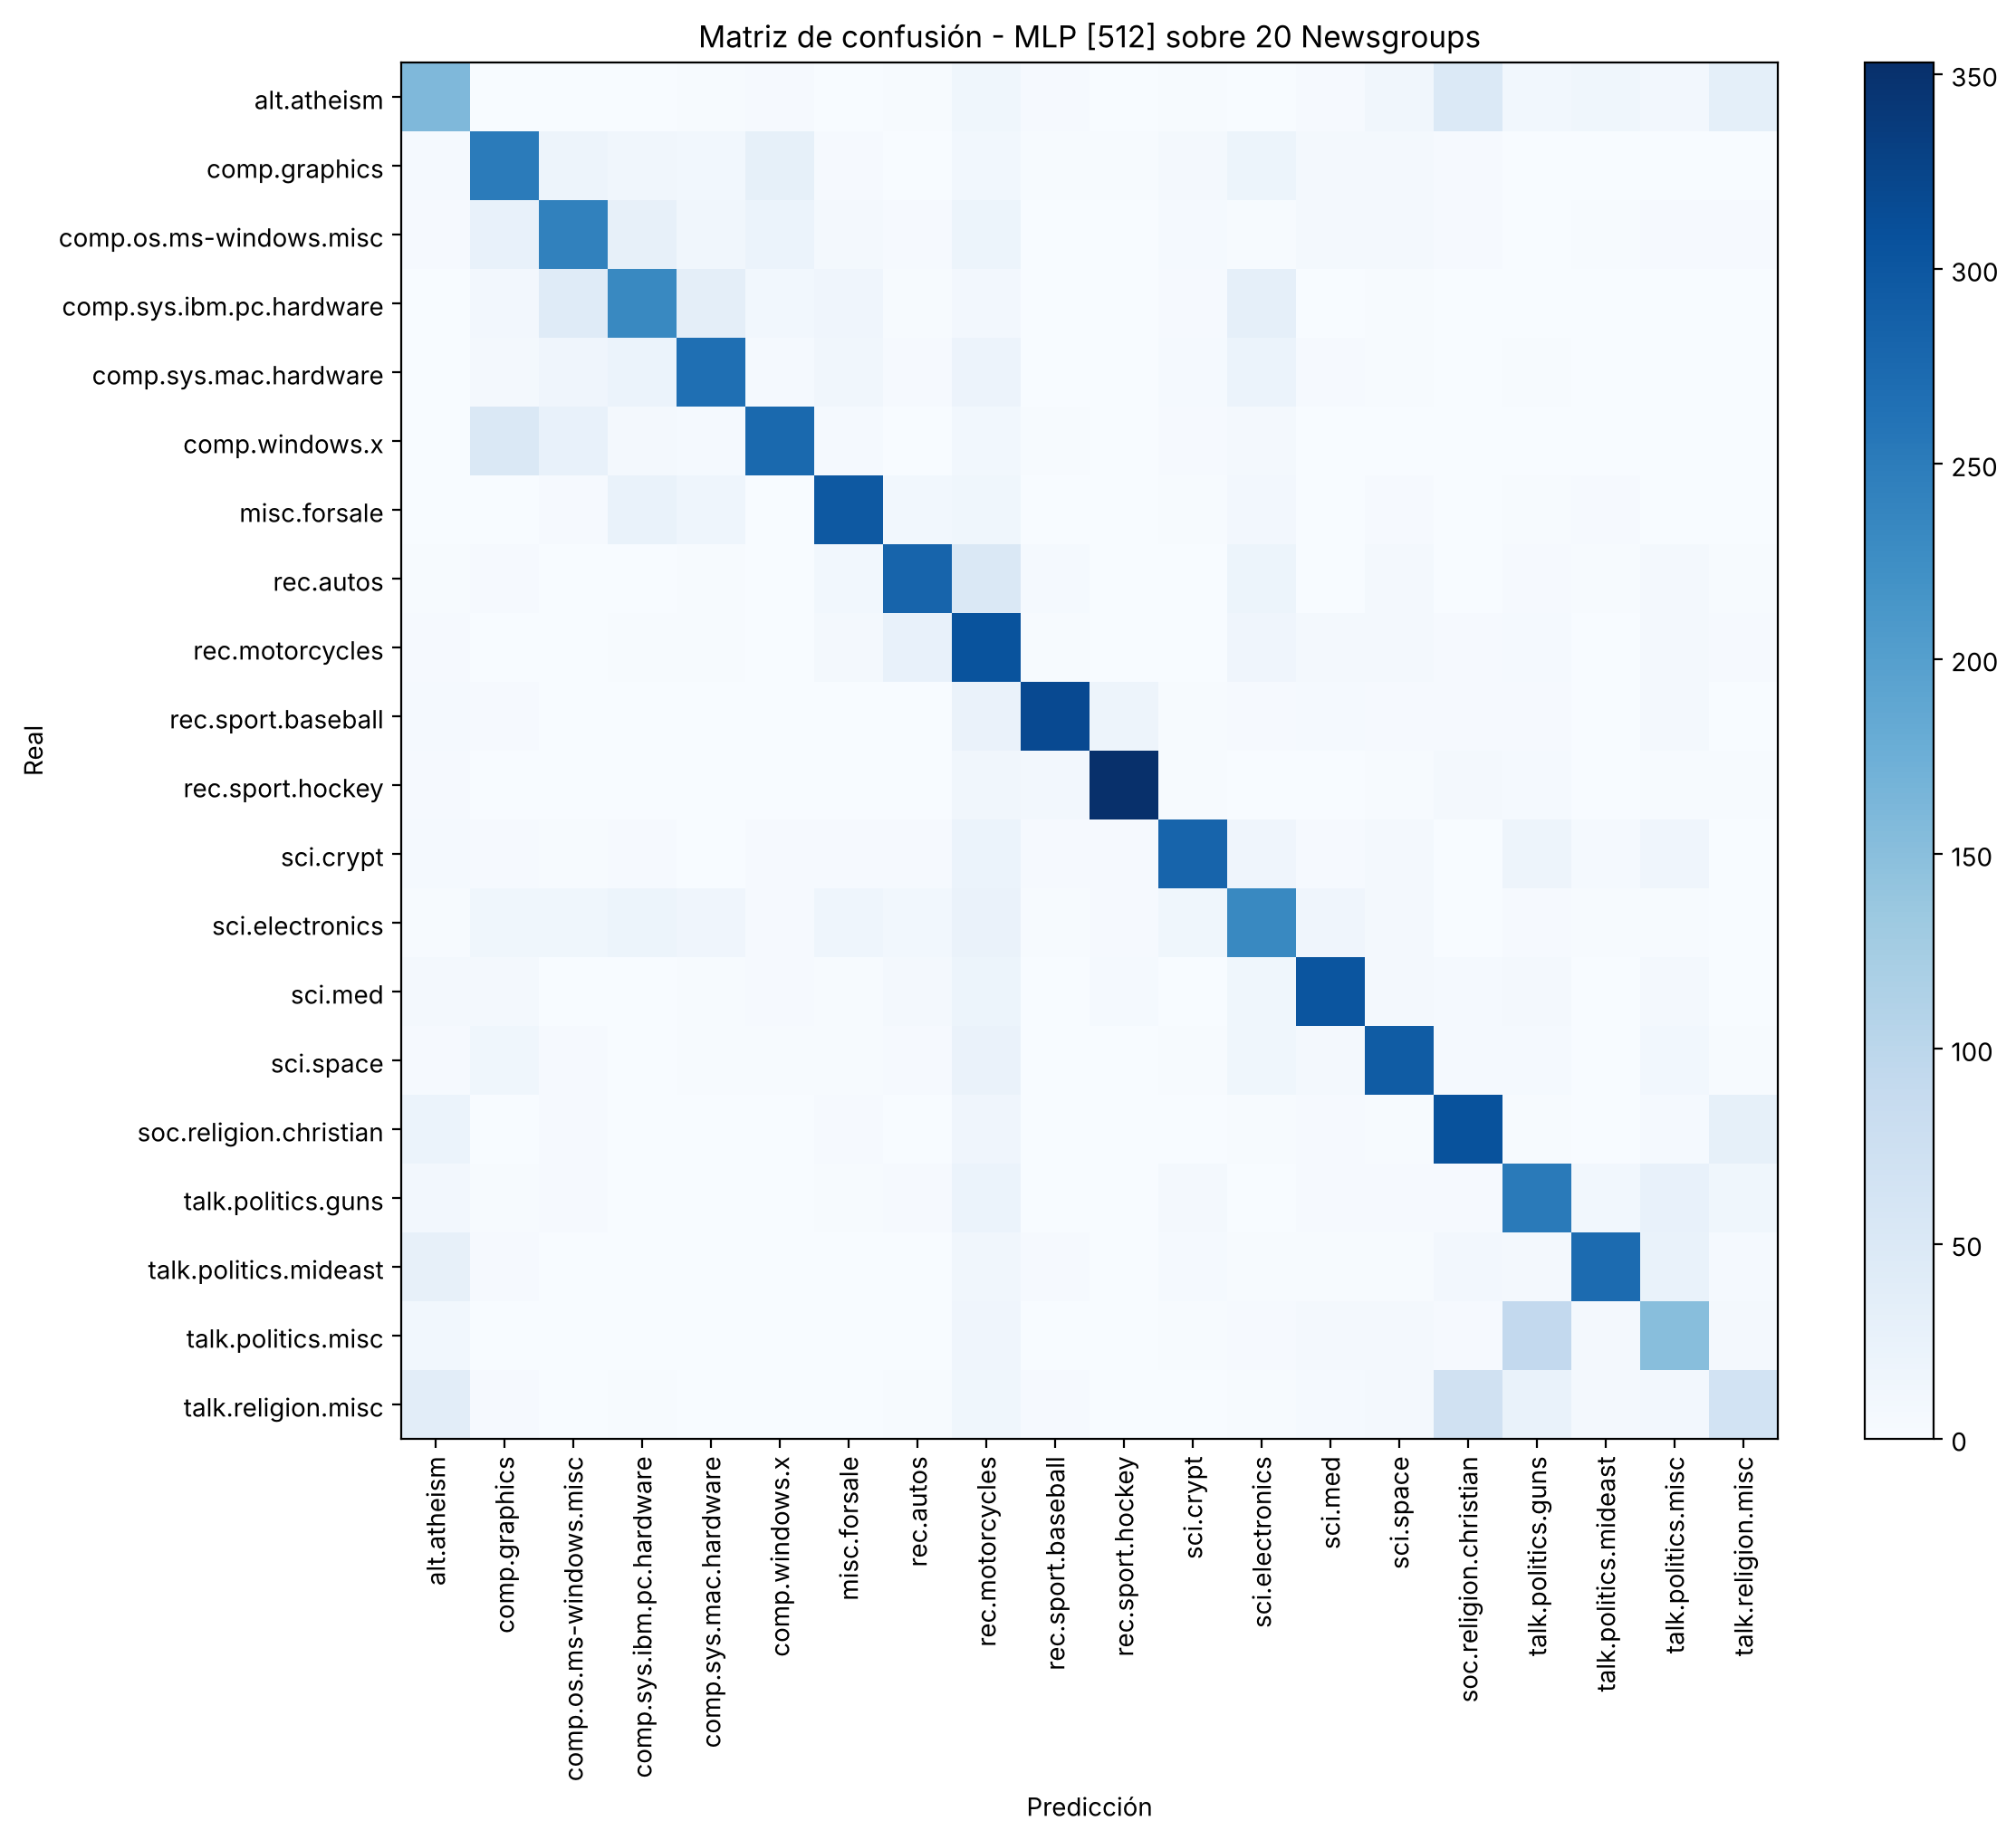

In [25]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión - MLP {BEST_HIDDEN_UNITS} sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

In [26]:
def top_confusions(labels, preds, k=10):
    cm_ = confusion_matrix(labels, preds)
    pairs = [(cm_[i, j], class_names[i], class_names[j])
             for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
    return sorted(pairs, reverse=True)[:k]

conf = pd.DataFrame({
    "MLP": [f"{r} → {p} ({n})" for n, r, p in top_confusions(all_labels, all_preds)],
    "Regresión softmax": [f"{r} → {p} ({n})" for n, r, p in top_confusions(labels_sm, preds_sm)],
}, index=range(1, 11))
pd.set_option("display.max_colwidth", 80)
display(conf)

,MLP,Regresión softmax
1,talk.politics.misc → talk.politics.guns (92),talk.politics.misc → talk.politics.guns (83)
2,talk.religion.misc → soc.religion.christian (70),talk.religion.misc → soc.religion.christian (66)
3,rec.autos → rec.motorcycles (50),comp.windows.x → comp.graphics (52)
4,comp.windows.x → comp.graphics (50),alt.atheism → soc.religion.christian (49)
5,alt.atheism → soc.religion.christian (49),comp.sys.ibm.pc.hardware → comp.os.ms-windows.misc (40)
6,comp.sys.ibm.pc.hardware → comp.os.ms-windows.misc (42),talk.religion.misc → alt.atheism (39)
7,talk.religion.misc → alt.atheism (37),comp.sys.mac.hardware → comp.sys.ibm.pc.hardware (37)
8,comp.sys.ibm.pc.hardware → comp.sys.mac.hardware (34),comp.sys.ibm.pc.hardware → comp.sys.mac.hardware (33)
9,alt.atheism → talk.religion.misc (33),comp.os.ms-windows.misc → comp.sys.ibm.pc.hardware (32)
10,comp.sys.ibm.pc.hardware → sci.electronics (31),rec.autos → rec.sport.baseball (31)


Las confusiones principales son las mismas en los dos modelos y siguen la estructura temática del dataset: `talk.politics.misc` → `talk.politics.guns`, `talk.religion.misc` → `soc.religion.christian`, `alt.atheism` → `soc.religion.christian`, `comp.windows.x` → `comp.graphics` y las de hardware/sistemas operativos entre sí. Son grupos que comparten gran parte del vocabulario, y las categorías "misc" mezclan por definición temas de sus categorías hermanas. Que el MLP no las resuelva indica que el problema está en la representación (bolsa de palabras TF-IDF), no en la capacidad del clasificador: si dos clases usan las mismas palabras, una no linealidad sobre esas mismas features no agrega mucha información.

## 9. Análisis: capas, unidades y sobreajuste (con repeticiones)

En la versión anterior concluía que "más capas y unidades empeoran" a partir de corridas únicas, y el propio mejor modelo (1 capa de 16 unidades, con menos parámetros que la softmax) contradecía esa conclusión. Acá lo pruebo con experimentos controlados: cambio un solo factor por vez, dejo el resto como en la mejor configuración de Optuna (preprocesamiento, optimizador, `lr`, activación y `batch_size`) y repito cada configuración con 3 semillas, sobre validación.

Para cada configuración reporto: el máximo de accuracy de validación, la **brecha train − validación** en la última época, la época de mínima loss de validación (a partir de ahí empieza el sobreajuste) y el tiempo por época.

Un límite de este diseño: el `lr` es el elegido para la mejor arquitectura. Una red mucho más profunda o más ancha podría necesitar otro `lr`, así que lo que medimos es el efecto de cambiar la arquitectura **manteniendo el resto fijo**, no el mejor resultado posible de cada arquitectura.

### 9.1. Regresión softmax vs. MLP

,config,n_seeds,n_params,peak_val_acc,epoch_peak,final_val_acc,gap_final,epoch_min_val_loss,time_per_epoch_s,time_to_99_s
0,softmax (0 capas),3,"200,020",0.7397 ± 0.0018,6.00 ± 1.41,0.7322 ± 0.0016,0.2367 ± 0.0015,15.00 ± 0.00,0.26 ± 0.01,0.72 ± 0.05
1,mejor MLP [512],3,"5,130,772",0.7444 ± 0.0019,5.67 ± 0.94,0.7313 ± 0.0006,0.2412 ± 0.0006,8.33 ± 0.47,1.67 ± 0.05,8.10 ± 1.09


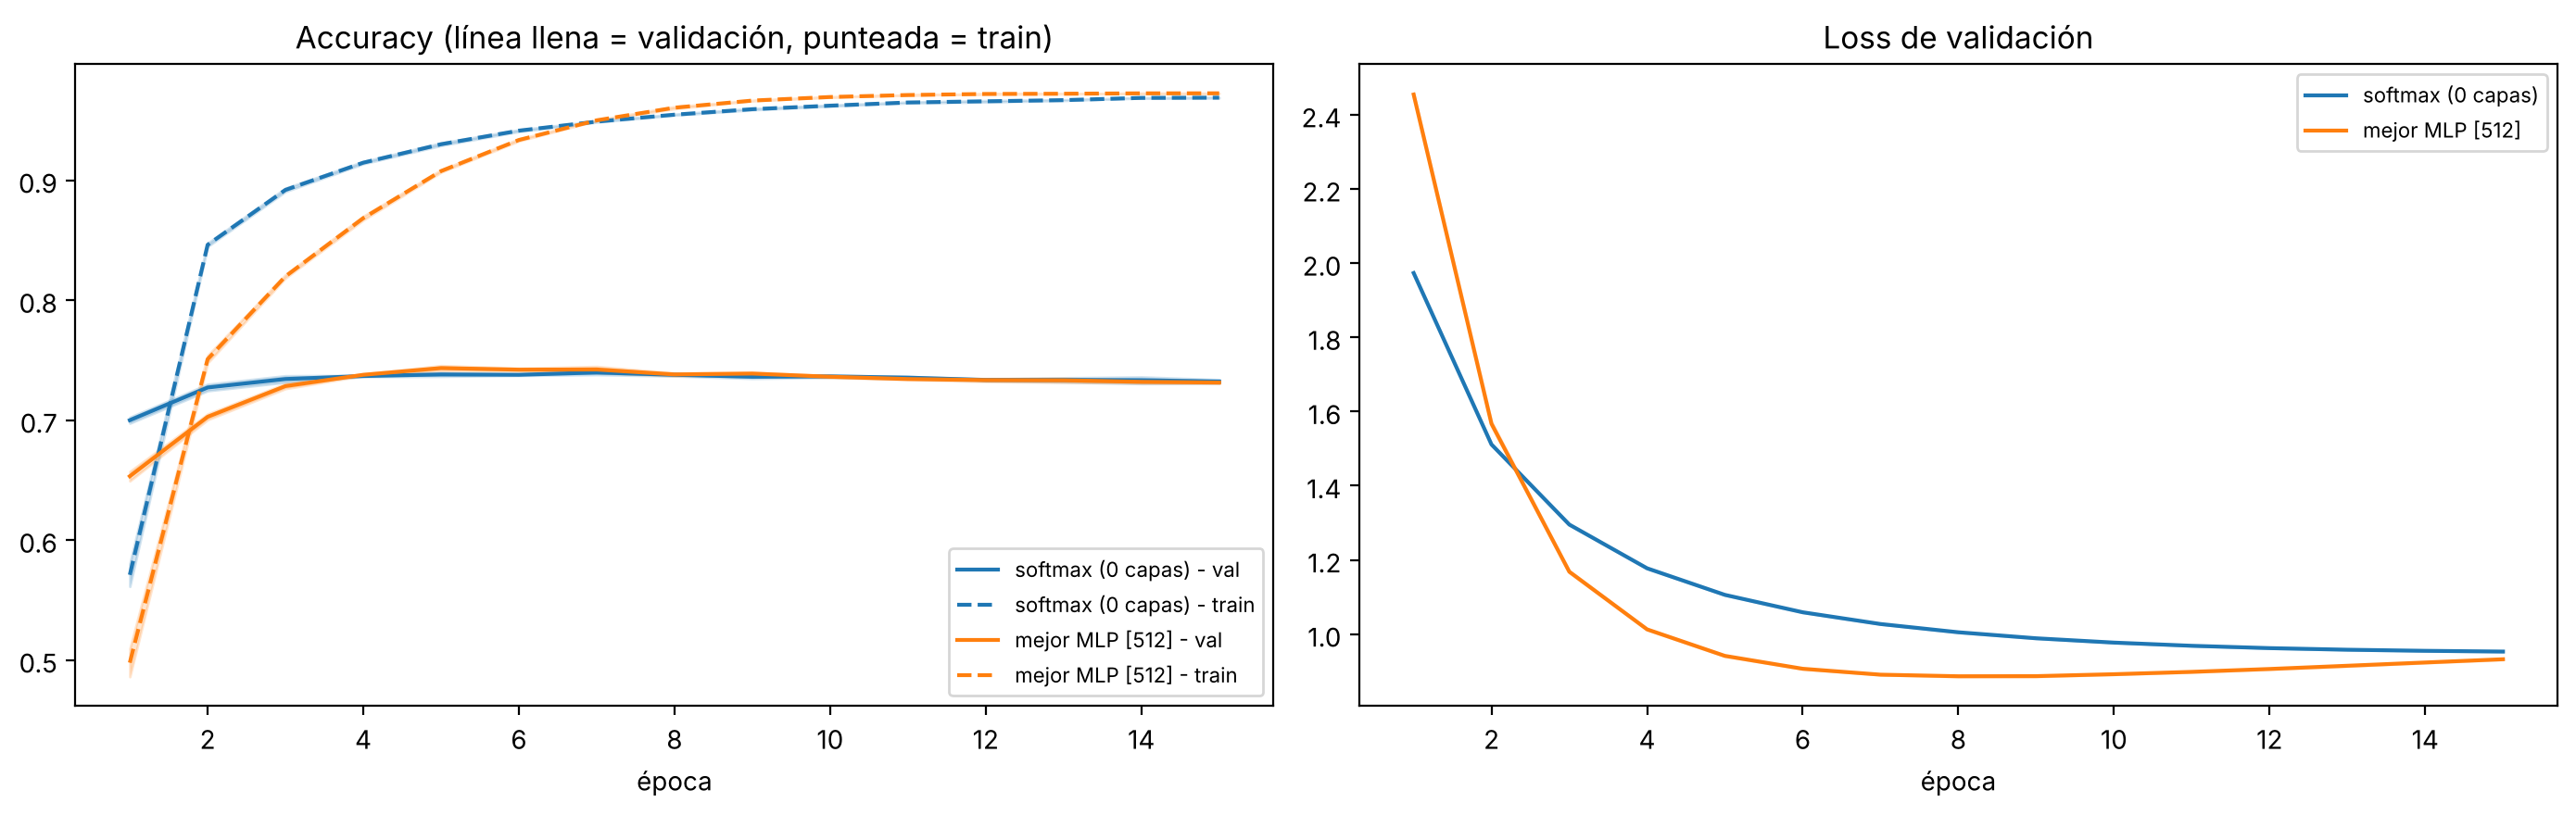

In [27]:
EPOCHS_ARCH = 15
hist_softmax_val, params_softmax = run_config(**SOFTMAX_CFG, epochs=EPOCHS_ARCH, seeds=SEEDS,
                                              tag="arch_softmax", experiment_type="arch_compare")
groups_cmp = {"softmax (0 capas)": hist_softmax_val, f"mejor MLP {BEST_HIDDEN_UNITS}": [
    {k: v[:EPOCHS_ARCH] for k, v in h.items()} for h in hist_dyn]}
params_cmp = {"softmax (0 capas)": params_softmax, f"mejor MLP {BEST_HIDDEN_UNITS}": params_mlp}
display(summary_table(groups_cmp, params_cmp))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for label, hs in groups_cmp.items():
    l = plot_mean_std(axes[0], hs, "val_acc", f"{label} - val")
    plot_mean_std(axes[0], hs, "train_acc", f"{label} - train", ls="--", color=l.get_color())
    plot_mean_std(axes[1], hs, "val_loss", label, color=l.get_color())
axes[0].set_title("Accuracy (línea llena = validación, punteada = train)"); axes[1].set_title("Loss de validación")
for ax in axes:
    ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

* En validación, el mejor MLP llega a **0.744 ± 0.002** y la regresión softmax a **0.740 ± 0.002**. La diferencia (~0.5 puntos) es consistente entre semillas, pero chica. Como referencia, el error estándar de una accuracy de ~0.74 sobre 2263 documentos de validación es ≈ 0.009.
* La brecha train − validación a las 15 épocas es casi igual: 0.24 en los dos. El MLP no sobreajusta mucho más que la softmax en esta comparación, pero **sobreajusta antes**: su loss de validación es mínima en la época ~8, mientras que la de la softmax todavía baja en la época 15.
* El costo es mucho mayor: 1.67 s por época contra 0.26 s (~6×), y ~8 s hasta llegar al 99% de su máximo contra ~0.7 s (~11×).
* **Por qué el MLP casi no mejora.** Con 10000 features TF-IDF y ~9000 documentos, el problema ya es casi linealmente separable en train (la softmax llega a ~0.97 de accuracy de train). Lo que limita la validación no es la capacidad del modelo, sino que las features (palabras sueltas) no alcanzan para distinguir categorías con vocabulario compartido. Una capa oculta puede combinar palabras, pero con tan pocos ejemplos por combinación esa capacidad extra se usa más para ajustar el train que para generalizar.

### 9.2. Efecto de la cantidad de capas

Ancho fijo de 128 unidades por capa, de 1 a 4 capas ocultas.

In [28]:
depth_groups, depth_params = {}, {}
for n_layers in [1, 2, 3, 4]:
    hidden = [128] * n_layers
    cfg = {**BEST_CFG, "hidden_units": hidden}
    label = f"{n_layers} capa(s) {hidden}"
    depth_groups[label], depth_params[label] = run_config(**cfg, epochs=EPOCHS_ARCH, seeds=SEEDS,
                                                           tag=f"arch_depth_{n_layers}", experiment_type="arch_depth")
    print(label, "listo")
display(summary_table(depth_groups, depth_params))

1 capa(s) [128] listo


2 capa(s) [128, 128] listo


3 capa(s) [128, 128, 128] listo


4 capa(s) [128, 128, 128, 128] listo


,config,n_seeds,n_params,peak_val_acc,epoch_peak,final_val_acc,gap_final,epoch_min_val_loss,time_per_epoch_s,time_to_99_s
0,1 capa(s) [128],3,"1,282,708",0.7441 ± 0.0006,11.33 ± 1.89,0.7394 ± 0.0022,0.2221 ± 0.0026,15.00 ± 0.00,0.54 ± 0.01,4.36 ± 0.07
1,"2 capa(s) [128, 128]",3,"1,299,220",0.7123 ± 0.0025,6.67 ± 0.47,0.6976 ± 0.0056,0.2748 ± 0.0055,6.33 ± 0.47,0.57 ± 0.02,3.17 ± 0.28
2,"3 capa(s) [128, 128, 128]",3,"1,315,732",0.6617 ± 0.0099,4.00 ± 0.00,0.6379 ± 0.0102,0.3339 ± 0.0102,4.00 ± 0.00,0.61 ± 0.02,2.48 ± 0.05
3,"4 capa(s) [128, 128, 128, 128]",3,"1,332,244",0.6254 ± 0.0143,4.00 ± 0.00,0.6022 ± 0.0202,0.3697 ± 0.0200,3.00 ± 0.00,0.63 ± 0.02,2.28 ± 0.19


### 9.3. Efecto de la cantidad de unidades

Una sola capa oculta, de 16 a 1024 unidades.

In [29]:
width_groups, width_params = {}, {}
for units in [16, 64, 256, 1024]:
    cfg = {**BEST_CFG, "hidden_units": [units]}
    label = f"1 capa [{units}]"
    width_groups[label], width_params[label] = run_config(**cfg, epochs=EPOCHS_ARCH, seeds=SEEDS,
                                                           tag=f"arch_width_{units}", experiment_type="arch_width")
    print(label, "listo")
display(summary_table(width_groups, width_params))

1 capa [16] listo


1 capa [64] listo


1 capa [256] listo


1 capa [1024] listo


,config,n_seeds,n_params,peak_val_acc,epoch_peak,final_val_acc,gap_final,epoch_min_val_loss,time_per_epoch_s,time_to_99_s
0,1 capa [16],3,"160,356",0.7048 ± 0.0042,15.00 ± 0.00,0.7048 ± 0.0042,0.1285 ± 0.0040,15.00 ± 0.00,0.26 ± 0.02,3.49 ± 0.21
1,1 capa [64],3,"641,364",0.7396 ± 0.0031,15.00 ± 0.00,0.7396 ± 0.0031,0.1955 ± 0.0015,15.00 ± 0.00,0.41 ± 0.01,4.32 ± 0.55
2,1 capa [256],3,"2,565,396",0.7441 ± 0.0006,7.33 ± 0.47,0.7344 ± 0.0006,0.2368 ± 0.0006,12.00 ± 0.00,0.93 ± 0.02,5.35 ± 0.60
3,1 capa [1024],3,"10,261,524",0.7430 ± 0.0009,4.33 ± 0.47,0.7275 ± 0.0021,0.2452 ± 0.0020,6.00 ± 0.00,3.35 ± 0.05,10.41 ± 0.03


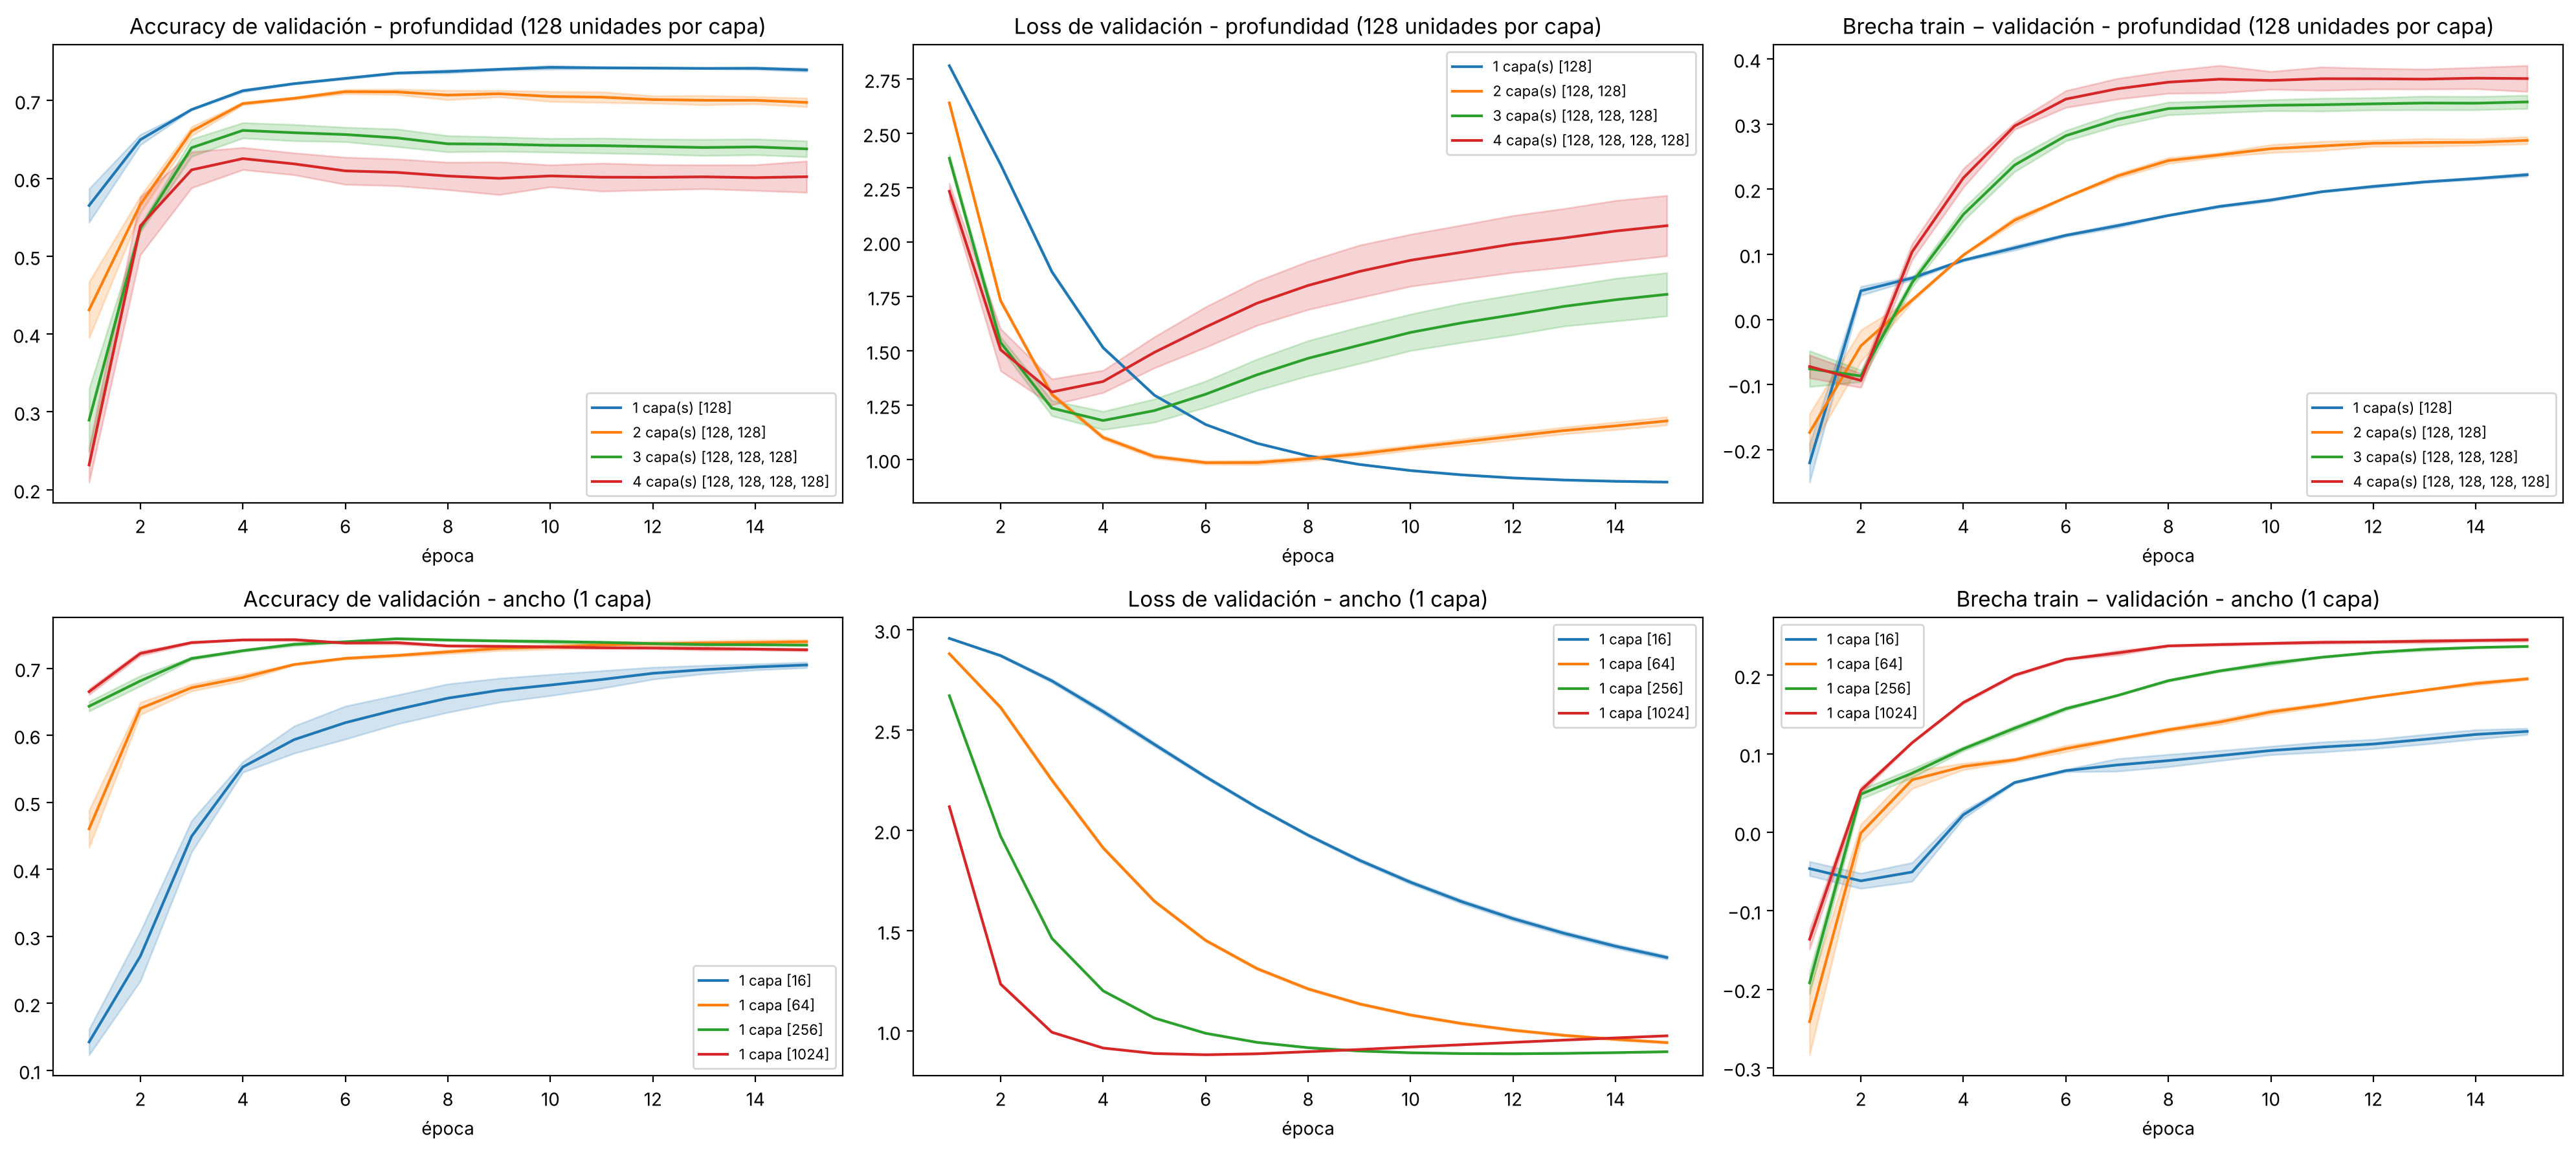

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for row, (groups, title) in enumerate([(depth_groups, "profundidad (128 unidades por capa)"),
                                       (width_groups, "ancho (1 capa)")]):
    for label, hs in groups.items():
        plot_mean_std(axes[row, 0], hs, "val_acc", label)
        plot_mean_std(axes[row, 1], hs, "val_loss", label)
        gap = [{"gap": np.array(h["train_acc"]) - np.array(h["val_acc"])} for h in hs]
        plot_mean_std(axes[row, 2], gap, "gap", label)
    axes[row, 0].set_title(f"Accuracy de validación - {title}")
    axes[row, 1].set_title(f"Loss de validación - {title}")
    axes[row, 2].set_title(f"Brecha train − validación - {title}")
    for ax in axes[row]:
        ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Profundidad (9.2).** Con el ancho fijo en 128, la cantidad de parámetros casi no cambia (de 1.28 a 1.33 millones, porque casi todos están en la primera capa), así que este experimento aísla el efecto de la profundidad:

| capas | máx. val_acc | brecha final | época de mínima val_loss |
|---|---|---|---|
| 1 | 0.744 ± 0.001 | 0.22 | 15 (todavía bajando) |
| 2 | 0.712 ± 0.003 | 0.27 | ~6 |
| 3 | 0.662 ± 0.010 | 0.33 | 4 |
| 4 | 0.625 ± 0.014 | 0.37 | 3 |

Las diferencias entre niveles (3 a 5 puntos) son mucho mayores que el desvío entre semillas, así que **en esta configuración sí se sostiene que más capas sobreajustan más y generalizan peor**: todas llegan a ~0.97 en train, pero las más profundas divergen antes y quedan peor en validación. También se vuelven más sensibles a la semilla (el desvío crece de 0.001 a 0.014). Hay que acotar la conclusión: el `lr`, la activación (Tanh) y la falta de regularización son los elegidos para 1 capa. Con otro `lr` o con dropout las redes profundas podrían mejorar, así que esto no dice que una red profunda no pueda funcionar en este problema.

**Ancho (9.3).** Con 1 capa, más unidades:
* **No empeoran el máximo:** 256 y 1024 unidades llegan al mismo máximo (~0.743-0.744). Lo que hacen es **adelantar el sobreajuste**: la época de mínima loss de validación pasa de 15 (16 y 64 unidades) a 12 (256) y 6 (1024), y la brecha final crece de 0.13 a 0.25. Más unidades significa más capacidad para memorizar, que hay que compensar cortando antes.
* **16 unidades** (160 mil parámetros, menos que la softmax) llegan a 0.705 y siguen subiendo en la época 15. Con 64 unidades también siguen subiendo. Las redes chicas convergen más lento con el `lr` elegido para 512 unidades, y además 16 unidades es un cuello de botella para 20 clases.

**Sobre la conclusión de la versión anterior.** Decía que "más capas y unidades empeoran". Con repeticiones se ve que eso vale para **las capas**, pero no para las unidades. Más unidades en una sola capa no bajan el máximo; solo hacen que el sobreajuste llegue antes. Tampoco es cierto que el MLP sea "demasiado complejo" por tener capas ocultas: el que había ganado antes (1 capa de 16 unidades) tenía menos parámetros que la softmax. Lo que importa es cuántos parámetros tiene y cuántas capas apila.

## 10. Búsqueda de la arquitectura que más sobreajusta

Se busca con Optuna la cantidad de capas (1 a 4) y de unidades que **maximiza** la brecha entre la accuracy de train y la de validación después de 10 épocas.

Correcciones respecto de la versión anterior:
* El texto decía que se fijaban los mejores hiperparámetros, pero el código usaba Adam con ReLU y el `lr` que había ganado con RMSprop. Ahora se usan **todos** los hiperparámetros de la mejor configuración (`BEST_CFG`: optimizador, `lr`, `momentum`, activación, `batch_size` y preprocesamiento) y solo se buscan las capas y unidades.
* El rango de unidades es el mismo que el de la búsqueda principal (16 a 1024).
* Cada trial fija la semilla y el sampler tiene semilla.
* Además de la brecha, se guarda la curva completa de cada trial para graficarla.

In [31]:
EPOCHS_OVERFIT = 10
N_TRIALS_OVERFIT = 15
_tr_texts, _val_texts = get_split_texts(BEST_CFG["remove_stopwords"], BEST_CFG["normalization"])
_X_tr, _X_val, _ = vectorize_data(_tr_texts, _val_texts, BEST_CFG["ngram_range"], BEST_CFG["max_features"], BEST_CFG["min_df"])
overfit_train_ds, overfit_val_ds = to_tensor_dataset(_X_tr, y_tr), to_tensor_dataset(_X_val, y_val)
overfit_histories = {}

def objective_overfit_search(trial):
    num_layers = trial.suggest_int("num_layers", 1, 4)
    hidden_units = [trial.suggest_categorical(f"units_layer_{i}", UNITS_CHOICES) for i in range(num_layers)]
    set_seed(SEED)
    train_loader, val_loader = make_loaders(overfit_train_ds, overfit_val_ds, BEST_CFG["batch_size"])
    model = SoftmaxRegression(_X_tr.shape[1], NUM_CLASSES, hidden_units, BEST_CFG["activation"])
    optimizer = make_optimizer(BEST_CFG["optimizer_name"], model.parameters(), BEST_CFG["lr"], BEST_CFG["momentum"])
    with mlflow.start_run(run_name=f"overfit_trial_{trial.number}"):
        mlflow.log_params({"hidden_units": str(hidden_units), "experiment_type": "overfit_search"})
        history = train_softmax_model(model, train_loader, val_loader, optimizer, EPOCHS_OVERFIT, verbose=False)
    s = summarize_history(history)
    overfit_histories[trial.number] = history
    trial.set_user_attr("hidden_units", str(hidden_units))
    trial.set_user_attr("n_params", count_params(model))
    for k in ["peak_val_acc", "final_val_acc", "final_train_acc", "epoch_min_val_loss", "time_per_epoch_s"]:
        trial.set_user_attr(k, float(s[k]))
    print(f"trial {trial.number:2d} | {str(hidden_units):24s} | brecha={s['gap_final']:.4f} "
          f"| val_acc={s['final_val_acc']:.4f} | {s['time_per_epoch_s']:.2f}s/época")
    return s["gap_final"]

overfit_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
overfit_study.optimize(objective_overfit_search, n_trials=N_TRIALS_OVERFIT)

df_over = pd.DataFrame([{"trial": t.number, "num_layers": t.params["num_layers"], **t.user_attrs, "brecha": t.value}
                        for t in overfit_study.trials])
display(df_over.sort_values("brecha", ascending=False).reset_index(drop=True).round(4))

trial  0 | [16, 128]                | brecha=0.1838 | val_acc=0.6867 | 0.27s/época


trial  1 | [256]                    | brecha=0.2175 | val_acc=0.7380 | 0.88s/época


trial  2 | [32, 128]                | brecha=0.2196 | val_acc=0.6982 | 0.30s/época


trial  3 | [256, 256, 64]           | brecha=0.3298 | val_acc=0.6412 | 0.96s/época


trial  4 | [32, 32]                 | brecha=0.1739 | val_acc=0.6863 | 0.29s/época


trial  5 | [256, 512, 256]          | brecha=0.3114 | val_acc=0.6597 | 1.00s/época


... (6 outputs left out)

trial 12 | [64, 16, 16, 512]        | brecha=0.3739 | val_acc=0.5904 | 0.40s/época


trial 13 | [1024, 16, 1024, 16]     | brecha=0.3575 | val_acc=0.5988 | 3.32s/época


trial 14 | [512, 1024, 32, 256]     | brecha=0.3238 | val_acc=0.6469 | 1.88s/época


,trial,num_layers,hidden_units,n_params,peak_val_acc,final_val_acc,final_train_acc,epoch_min_val_loss,time_per_epoch_s,brecha
0,10,4,"[512, 16, 16, 512]",5147956,0.6080,0.5895,0.9705,3.0,1.6092,0.3810
1,11,4,"[512, 16, 16, 512]",5147956,0.6080,0.5895,0.9705,3.0,1.6092,0.3810
2,12,4,"[64, 16, 16, 512]",660340,0.6027,0.5904,0.9643,5.0,0.3996,0.3739
3,7,4,"[512, 32, 16, 512]",5156420,0.6359,0.6138,0.9714,2.0,1.7148,0.3576
4,13,4,"[1024, 16, 1024, 16]",10291572,0.6098,0.5988,0.9562,8.0,3.3177,0.3575
5,3,3,"[256, 256, 64]",2643796,0.6703,0.6412,0.9709,4.0,0.9581,0.3298
6,9,3,"[16, 32, 512]",187716,0.6257,0.6182,0.9441,6.0,0.2932,0.3259
7,14,4,"[512, 1024, 32, 256]",5692212,0.6646,0.6469,0.9707,2.0,1.8806,0.3238
8,5,3,"[256, 512, 256]",2828308,0.6761,0.6597,0.9712,2.0,1.0040,0.3114
9,6,2,"[1024, 64]",10307924,0.7163,0.7039,0.9724,5.0,3.4170,0.2684


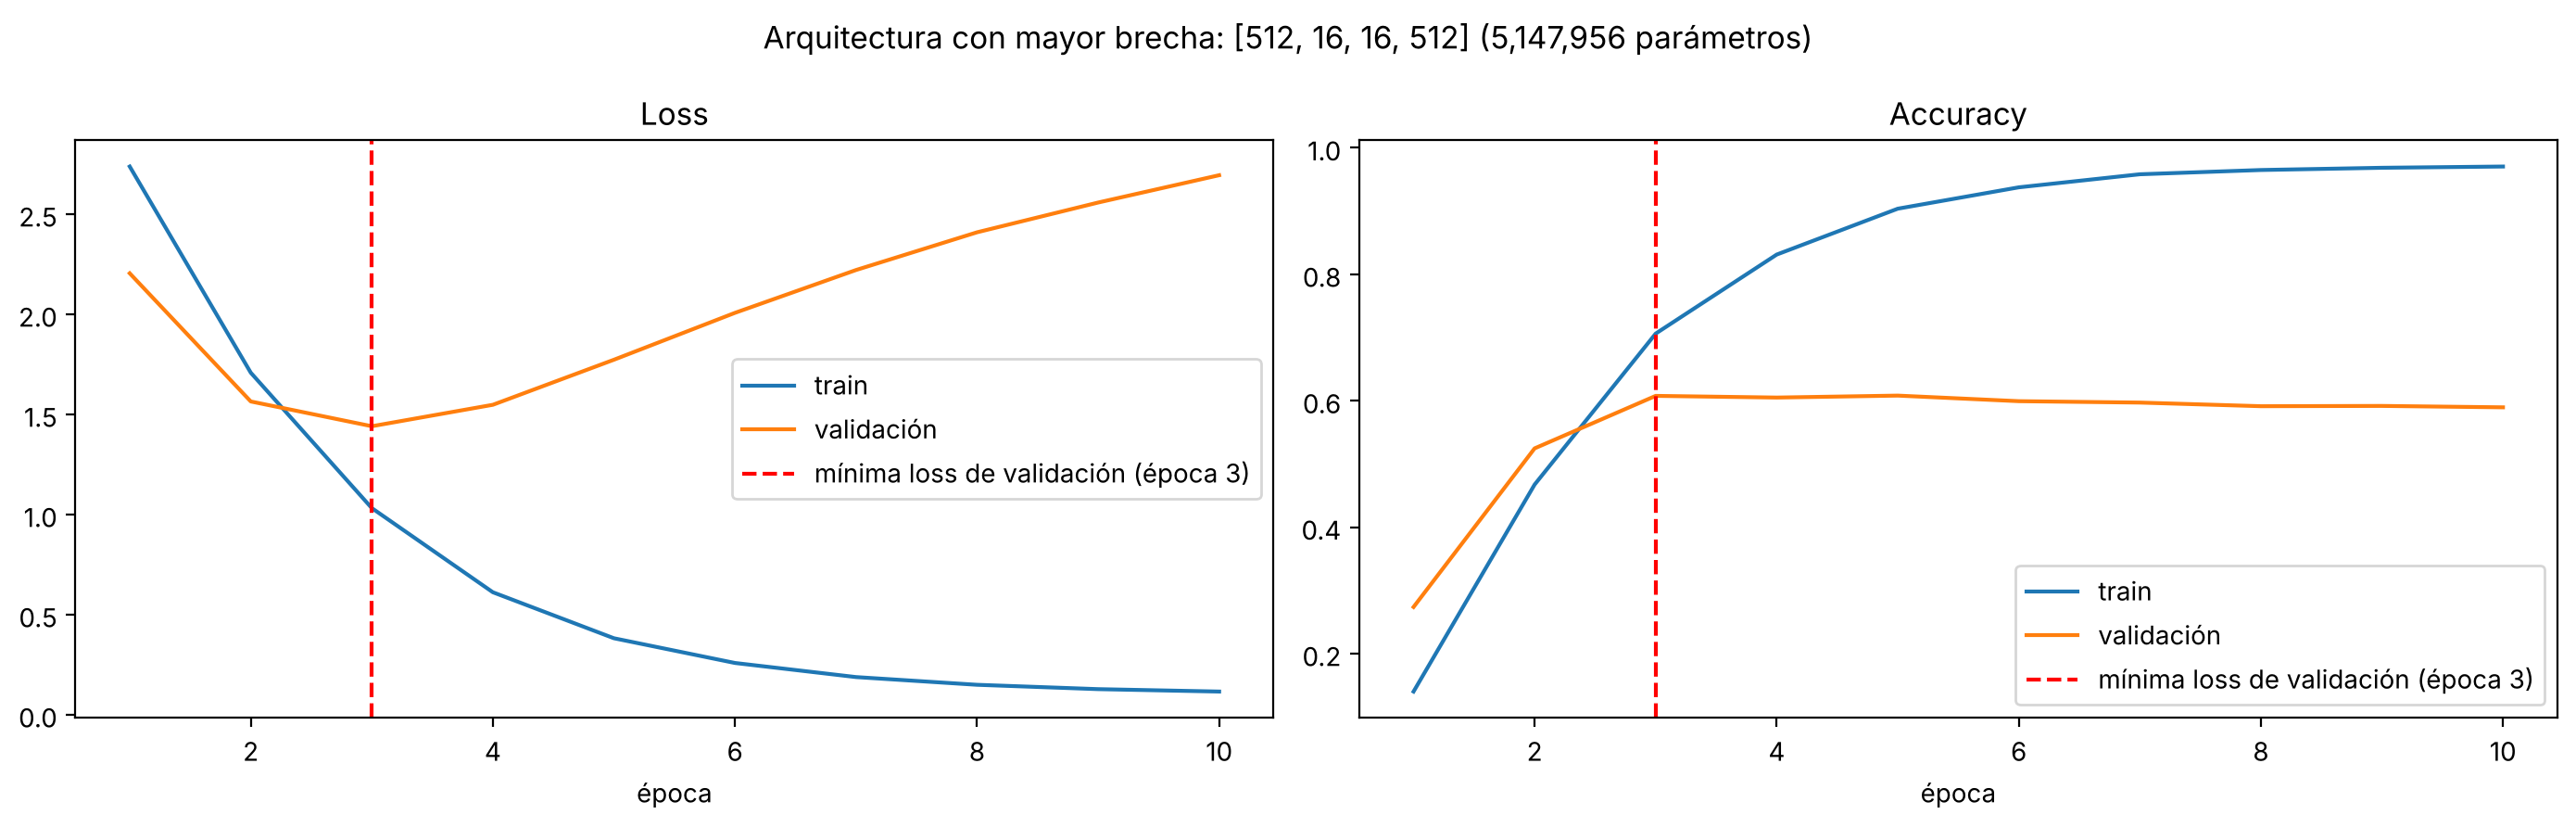

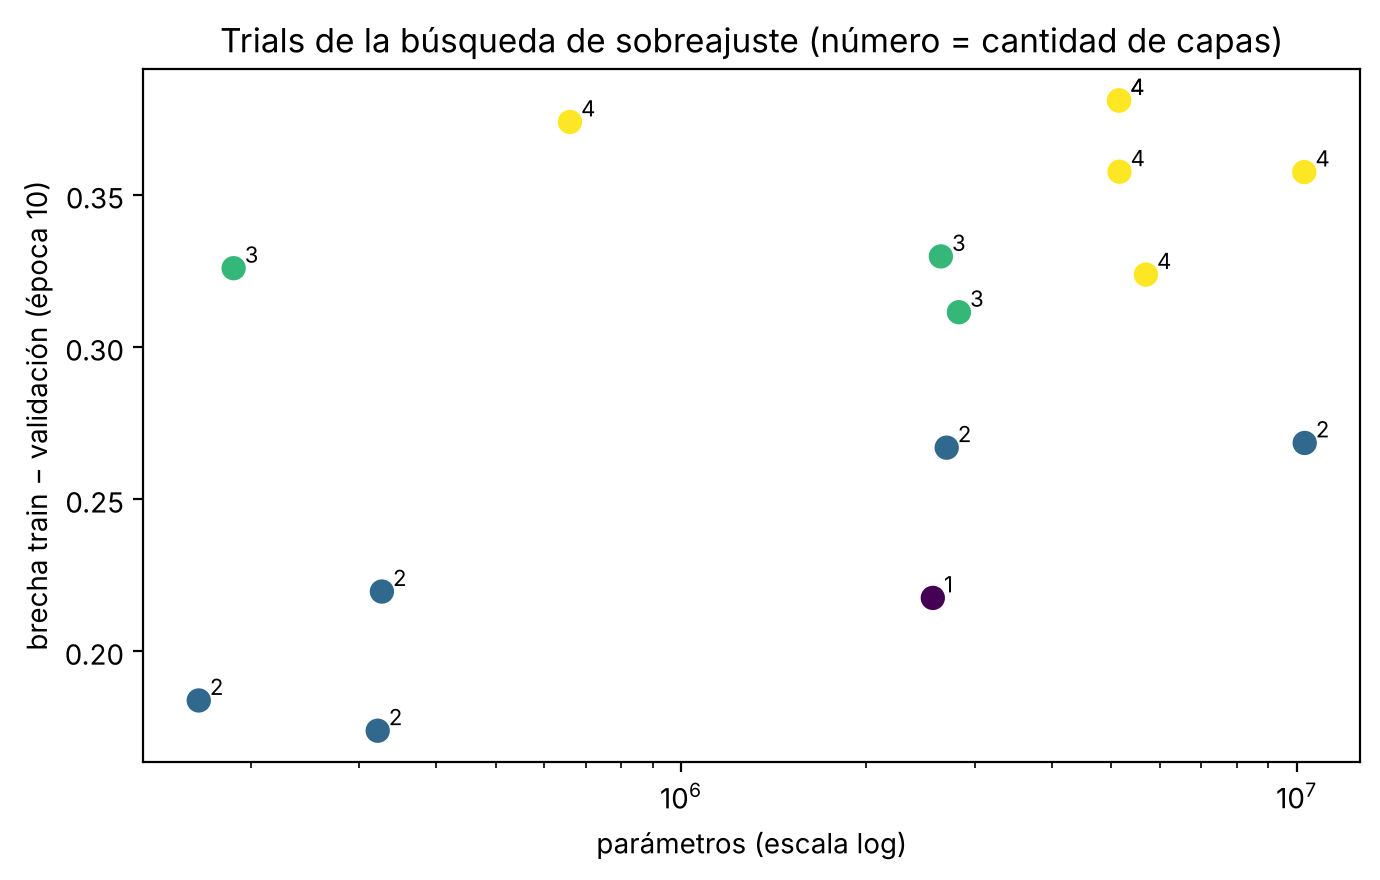

In [32]:
# Curvas train vs. validación del trial que más sobreajusta, marcando el punto de divergencia
best_over = overfit_study.best_trial
h = overfit_histories[best_over.number]
ep = np.arange(1, EPOCHS_OVERFIT + 1)
div = int(np.argmin(h["val_loss"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ep, h["train_loss"], label="train"); axes[0].plot(ep, h["val_loss"], label="validación")
axes[1].plot(ep, h["train_acc"], label="train"); axes[1].plot(ep, h["val_acc"], label="validación")
for ax, t in zip(axes, ["Loss", "Accuracy"]):
    ax.axvline(div, color="red", ls="--", label=f"mínima loss de validación (época {div})")
    ax.set_title(t); ax.set_xlabel("época"); ax.legend()
fig.suptitle(f"Arquitectura con mayor brecha: {best_over.user_attrs['hidden_units']} "
             f"({best_over.user_attrs['n_params']:,} parámetros)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df_over["n_params"], df_over["brecha"], c=df_over["num_layers"], cmap="viridis", s=60)
for _, r in df_over.iterrows():
    ax.annotate(int(r["num_layers"]), (r["n_params"], r["brecha"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("parámetros (escala log)"); ax.set_ylabel("brecha train − validación (época 10)")
ax.set_title("Trials de la búsqueda de sobreajuste (número = cantidad de capas)")
plt.tight_layout(); plt.show()

Una sola corrida por arquitectura no alcanza para decir que una sobreajusta más que otra: la brecha también cambia con la inicialización. Repito con 3 semillas las 3 arquitecturas con mayor brecha y la de menor brecha, y veo si las diferencias superan la variación entre semillas.

,config,n_seeds,n_params,peak_val_acc,epoch_peak,final_val_acc,gap_final,epoch_min_val_loss,time_per_epoch_s,time_to_99_s
0,"[512, 16, 16, 512]",3,"5,147,956",0.6100 ± 0.0208,4.33 ± 0.47,0.5867 ± 0.0230,0.3846 ± 0.0230,2.67 ± 0.47,1.64 ± 0.02,4.82 ± 0.31
1,"[64, 16, 16, 512]",3,"660,340",0.5963 ± 0.0193,5.33 ± 1.25,0.5734 ± 0.0291,0.3911 ± 0.0285,4.00 ± 0.82,0.42 ± 0.01,2.15 ± 0.37
2,"[32, 32]",3,"321,748",0.6768 ± 0.0071,10.00 ± 0.00,0.6768 ± 0.0071,0.1803 ± 0.0056,10.00 ± 0.00,0.28 ± 0.00,2.61 ± 0.12


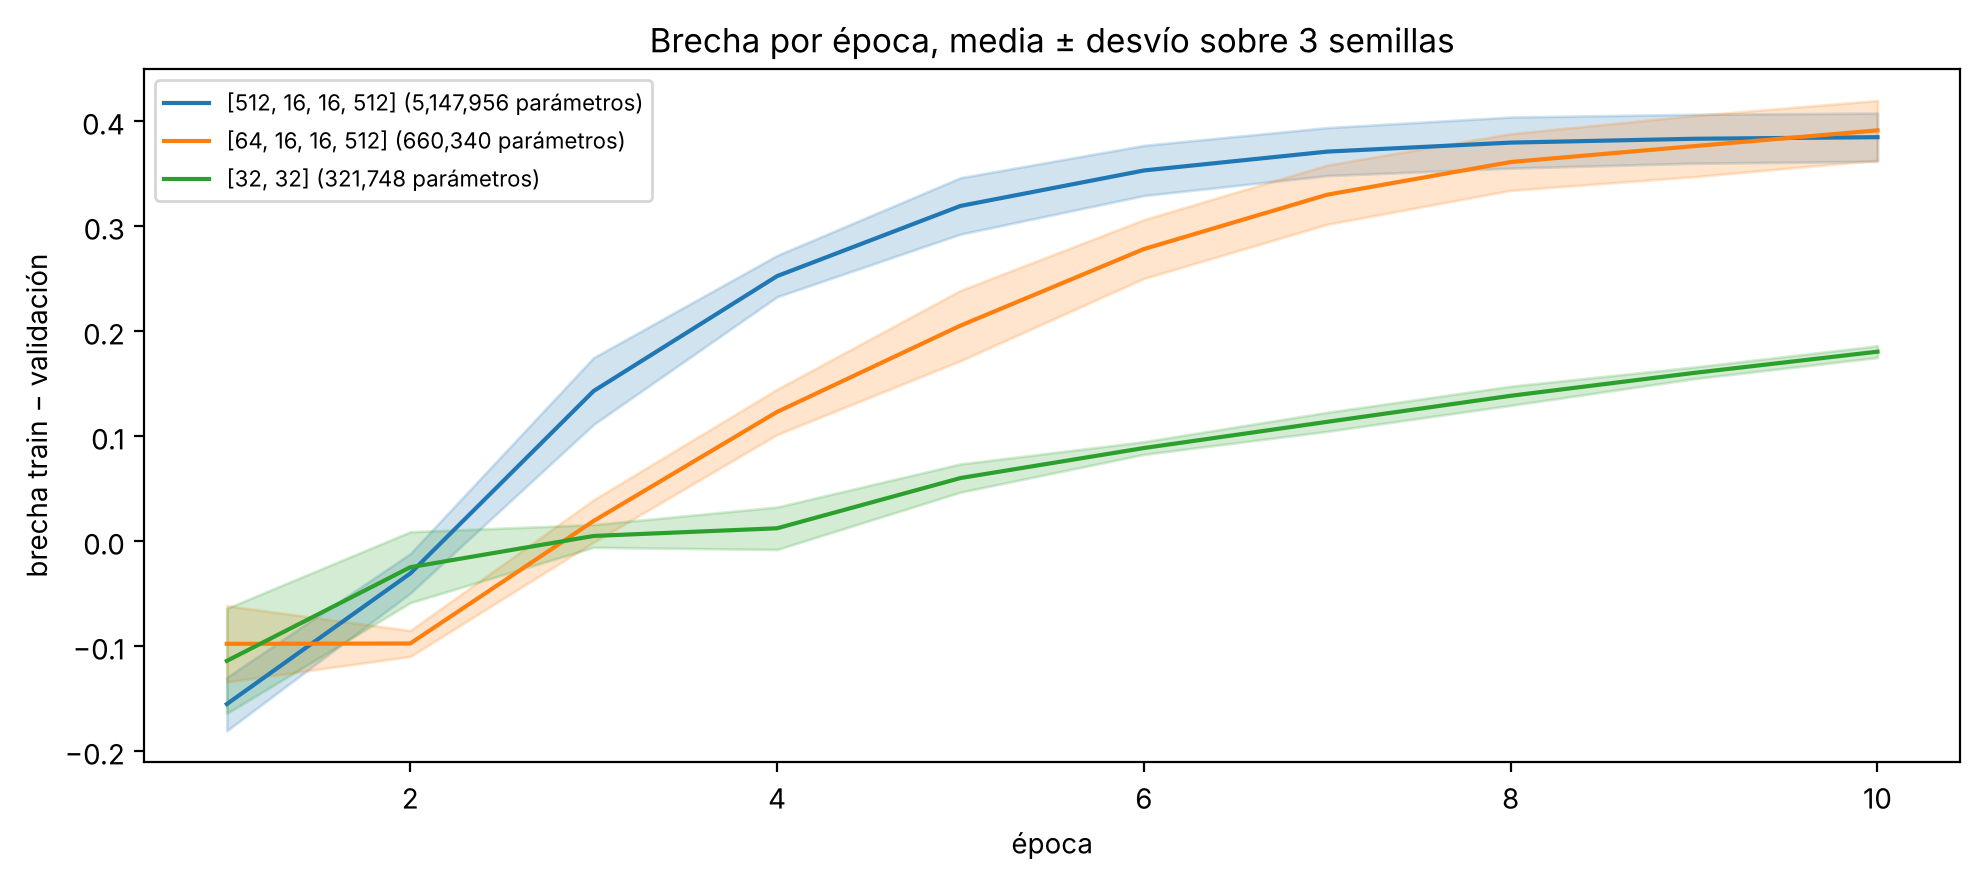

In [33]:
ranked = sorted(overfit_study.trials, key=lambda t: t.value, reverse=True)
selected, seen = [], set()
for t in ranked[:3] + [ranked[-1]]:
    key = t.user_attrs["hidden_units"]
    if key not in seen:
        selected.append(t); seen.add(key)

rep_groups, rep_params = {}, {}
for t in selected:
    hidden = [t.params[f"units_layer_{i}"] for i in range(t.params["num_layers"])]
    label = f"{hidden}"
    rep_groups[label], rep_params[label] = run_config(**{**BEST_CFG, "hidden_units": hidden}, epochs=EPOCHS_OVERFIT,
                                                       seeds=SEEDS, tag=f"overfit_rep_{t.number}",
                                                       experiment_type="overfit_repeat")
display(summary_table(rep_groups, rep_params))

fig, ax = plt.subplots(figsize=(10, 4.5))
for label, hs in rep_groups.items():
    gap = [{"gap": np.array(h["train_acc"]) - np.array(h["val_acc"])} for h in hs]
    plot_mean_std(ax, gap, "gap", f"{label} ({rep_params[label]:,} parámetros)")
ax.set_xlabel("época"); ax.set_ylabel("brecha train − validación"); ax.legend(fontsize=8)
ax.set_title("Brecha por época, media ± desvío sobre 3 semillas")
plt.tight_layout(); plt.show()

**Resultados de la búsqueda de sobreajuste**

* **Arquitectura con mayor brecha:** [512, 16, 16, 512], 4 capas y 5.1 millones de parámetros, con una brecha de 0.38. La siguen otras arquitecturas de 4 capas con un "cuello de botella" de 16 unidades en el medio ([64, 16, 16, 512]: 0.37; [512, 32, 16, 512] y [1024, 16, 1024, 16]: 0.36). En la versión anterior también había ganado una red de 4 capas ([32, 128, 128, 64]), con hiperparámetros que no eran los que decía el texto.
* **Punto de divergencia:** en la arquitectura ganadora, la loss de validación es mínima en la **época 3** (≈ 1.44) y después sube sin parar, hasta ~2.7 en la época 10. La accuracy de validación se estanca en ~0.60 mientras la de train sigue hasta 0.97. Desde la época 3 el modelo solo memoriza el train.
* **Menor brecha:** [32, 32] (0.17) y [16, 128] (0.18). Ojo con leer esto como "no sobreajustan": tienen poca brecha en parte porque **no terminan de ajustar el train** en 10 épocas (0.86-0.87 de accuracy de train). La brecha depende tanto de qué tan bien ajusta el train como de qué tan mal generaliza.
* **Profundidad vs. parámetros:** en el gráfico de dispersión, la brecha se ordena mucho más por cantidad de capas que por cantidad de parámetros. [64, 16, 16, 512] (660 mil parámetros) tiene más brecha que [1024, 64] (10 millones). Coincide con el experimento controlado de 9.2.
* **Con repeticiones (3 semillas):** [512, 16, 16, 512] da 0.385 ± 0.023 y [64, 16, 16, 512] da 0.391 ± 0.029. Están dentro del ruido entre semillas, así que **no se puede decir cuál de las dos sobreajusta más**: que una haya "ganado" la búsqueda es azar de la inicialización. Lo mismo valía para la versión anterior: la arquitectura ganadora de una corrida sin repeticiones no se puede tomar como "la" que más sobreajusta. Lo que sí es robusto es la diferencia con [32, 32] (0.180 ± 0.006): más del doble, muy por encima del desvío. (Los trials 10 y 11 propusieron la misma arquitectura, por eso se repiten 3 configuraciones y no 4.)

## 11. Análisis de tiempos

En la versión anterior la tabla de tiempos salía de la duración de los runs de MLflow: mezclaba corridas de ejecuciones previas del notebook (había trials repetidos y dos `softmax_final`), incluía el tiempo de logging y de guardar el modelo, y comparaba corridas con distinta cantidad de épocas. Ahora el tiempo se mide en el código, por época, y solo se comparan corridas de este notebook con el mismo preprocesamiento y el mismo `batch_size` (los experimentos controlados de las secciones 9 y 10).

,experimento,config,parámetros,s / época,desvío s / época,épocas al 99% del máximo,s al 99% del máximo,máx. val_acc
0,ancho,1 capa [16],160356,0.264,0.016,13.333,3.488,0.705
1,softmax vs MLP,softmax (0 capas),200020,0.258,0.011,3.000,0.722,0.740
2,sobreajuste,"[32, 32]",321748,0.280,0.002,9.333,2.611,0.677
3,ancho,1 capa [64],641364,0.410,0.012,10.333,4.319,0.740
4,sobreajuste,"[64, 16, 16, 512]",660340,0.420,0.014,5.000,2.148,0.596
5,profundidad,1 capa(s) [128],1282708,0.538,0.012,8.333,4.364,0.744
6,profundidad,"2 capa(s) [128, 128]",1299220,0.568,0.018,5.667,3.169,0.712
7,profundidad,"3 capa(s) [128, 128, 128]",1315732,0.610,0.017,4.000,2.481,0.662
8,profundidad,"4 capa(s) [128, 128, 128, 128]",1332244,0.632,0.024,3.667,2.277,0.625
9,ancho,1 capa [256],2565396,0.930,0.024,5.667,5.349,0.744


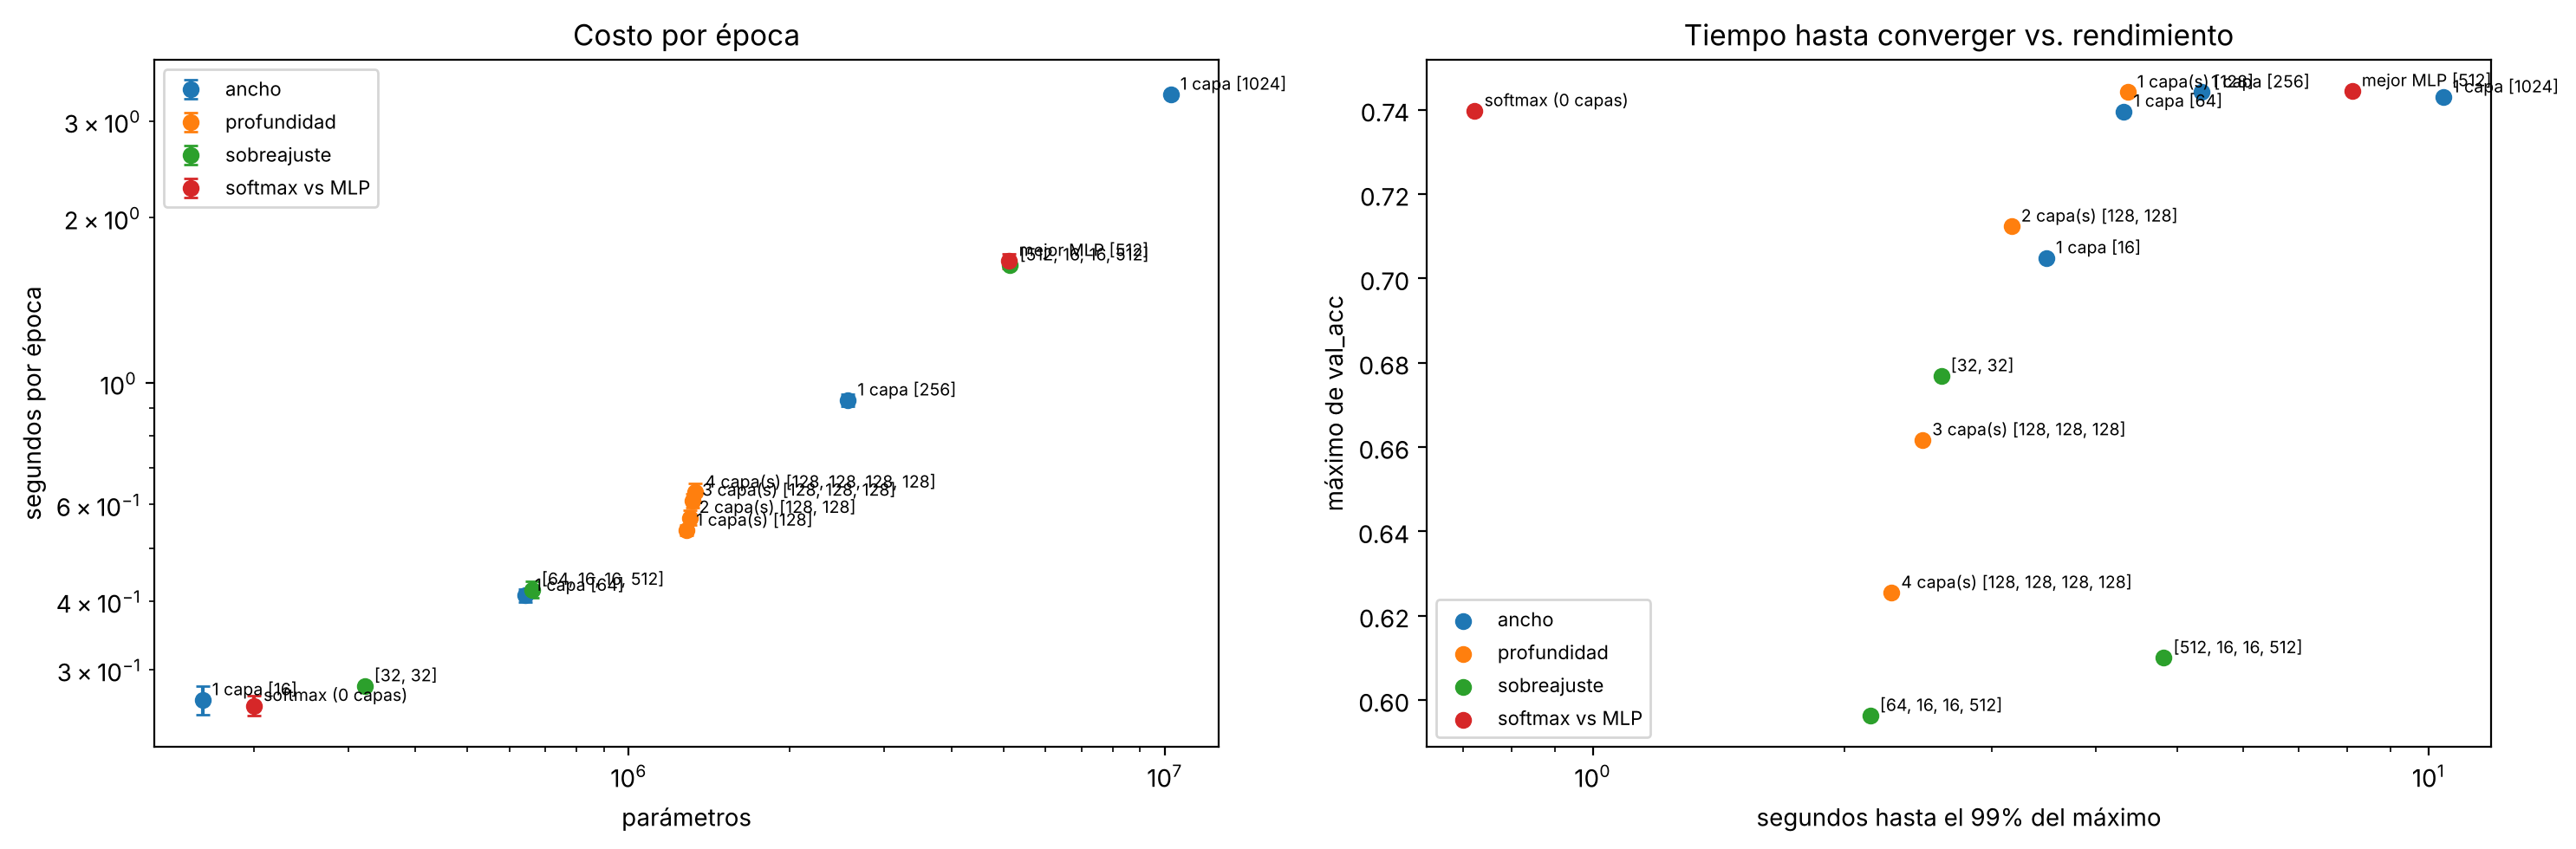

In [34]:
time_rows = []
for groups, params, exp in [(groups_cmp, params_cmp, "softmax vs MLP"), (depth_groups, depth_params, "profundidad"),
                            (width_groups, width_params, "ancho"), (rep_groups, rep_params, "sobreajuste")]:
    for label, hs in groups.items():
        s = pd.DataFrame([summarize_history(h) for h in hs])
        time_rows.append({"experimento": exp, "config": label, "parámetros": params[label],
                          "s / época": s["time_per_epoch_s"].mean(), "desvío s / época": s["time_per_epoch_s"].std(ddof=0),
                          "épocas al 99% del máximo": s["epoch_99"].mean(), "s al 99% del máximo": s["time_to_99_s"].mean(),
                          "máx. val_acc": s["peak_val_acc"].mean()})
df_time = pd.DataFrame(time_rows).drop_duplicates("config").sort_values("parámetros").reset_index(drop=True)
display(df_time.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for exp, g in df_time.groupby("experimento"):
    axes[0].errorbar(g["parámetros"], g["s / época"], yerr=g["desvío s / época"], fmt="o", label=exp, capsize=3)
    axes[1].scatter(g["s al 99% del máximo"], g["máx. val_acc"], label=exp)
for _, r in df_time.iterrows():
    axes[0].annotate(r["config"], (r["parámetros"], r["s / época"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
    axes[1].annotate(r["config"], (r["s al 99% del máximo"], r["máx. val_acc"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("parámetros"); axes[0].set_ylabel("segundos por época"); axes[0].set_title("Costo por época")
axes[1].set_xscale("log"); axes[1].set_xlabel("segundos hasta el 99% del máximo"); axes[1].set_ylabel("máximo de val_acc")
axes[1].set_title("Tiempo hasta converger vs. rendimiento")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Qué configuraciones son más costosas y por qué**

* **El tiempo por época lo domina la primera capa.** Con 10000 features de entrada, la primera capa tiene 10000 × (unidades) pesos, y cada paso hace un producto de matrices de batch × 10000 × unidades (más el backward). Por encima de ~1 millón de parámetros, el tiempo por época crece casi en proporción: 1.3 M → 0.54 s, 2.6 M → 0.93 s, 5.1 M → 1.67 s y 10.3 M → 3.36 s (duplicar parámetros ≈ duplicar el tiempo).
* **Por debajo de ~300 mil parámetros el tiempo ya no baja:** la softmax (200 mil) y la red de 16 unidades (160 mil) tardan lo mismo, ~0.26 s por época. Ahí domina el costo fijo de cada paso (armar los batches, lanzar operaciones chicas, calcular la loss), no la multiplicación.
* **Agregar capas chicas cuesta poco:** de 1 a 4 capas de 128 el tiempo por época sube solo de 0.54 a 0.63 s (+17%), porque cada capa extra tiene 16 mil parámetros contra 1.28 millones de la primera. La profundidad tiene mucho más efecto sobre el sobreajuste (9.2) que sobre el tiempo.
* **El `batch_size` también pesa:** en la búsqueda, una capa de 1024 unidades tarda ~16 s por época con batch 32 y ~3.4 s con batch 128. Con batches más chicos hay 4 veces más pasos, cada uno con su costo fijo, y matrices más chicas que aprovechan peor el hardware. Por eso esta tabla solo compara corridas con el mismo `batch_size` (128) y el mismo preprocesamiento.
* **Tiempo hasta converger** = épocas × tiempo por época. La softmax llega al 99% de su máximo en ~0.7 s; el mejor MLP necesita ~8 s, y una capa de 1024 unidades ~10 s, para quedar en la misma accuracy. Las redes profundas llegan antes a su máximo (en 2-3 s), pero porque ese máximo es más bajo y divergen enseguida. Las redes chicas (16 o 64 unidades) son baratas por época pero necesitan muchas más épocas.
* Todos los tiempos son en CPU. En GPU las diferencias entre modelos medianos se achican mucho (el costo fijo por paso pesa más), pero el orden se mantiene para los modelos más grandes.

**Relación costo-beneficio:** para este dataset, la regresión softmax da prácticamente la misma accuracy que el mejor MLP (0.740 contra 0.744 en validación) con 25 veces menos parámetros y ~11 veces menos tiempo hasta converger.

## 12. Conclusiones

1. **MLP vs. regresión softmax.** El mejor MLP (1 capa de 512 con Tanh, Adam) es levemente mejor que la softmax: 0.744 contra 0.740 en validación (media de 3 semillas) y 0.682 contra 0.675 en test. Corrige la conclusión anterior, que se basaba en una evaluación del test que no correspondía al modelo final. La mejora es chica y cuesta 25 veces más parámetros y ~6 veces más tiempo por época.
2. **Capas vs. unidades.** Con repeticiones, **agregar capas** sí empeora la validación y adelanta el sobreajuste, de forma clara y por encima del ruido entre semillas (con el `lr` y la activación fijos, sin regularización). **Agregar unidades** en una sola capa no empeora el máximo: solo hace que el sobreajuste llegue antes. Que haya capas ocultas no implica más complejidad: un MLP de 1 capa de 16 tiene menos parámetros que la softmax.
3. **Sobreajuste.** Las arquitecturas que más sobreajustan son las de 4 capas con un cuello de botella angosto en el medio. Divergen a partir de la época ~3. Entre las que más sobreajustan, las diferencias están dentro del ruido entre semillas, así que no tiene sentido elegir una ganadora puntual.
4. **Búsqueda.** SGD necesita un rango de `lr` propio y aun así es frágil en el MLP. La sigmoide aprende más lento y el pruner la penaliza. Con 5 épocas y poda temprana, la búsqueda favorece configuraciones de convergencia rápida, y con 40 trials todavía estaba mejorando al final.
5. **Tiempo.** Lo determina casi por completo el tamaño de la primera capa (10000 × unidades) y el `batch_size`. La profundidad agrega poco tiempo, pero mucho sobreajuste.
6. **Lo que limita el rendimiento** no es la capacidad del modelo, sino la representación: las confusiones entre categorías con vocabulario compartido son las mismas en los dos modelos. Para mejorar habría que cambiar las features (por ejemplo, embeddings) o regularizar el MLP (dropout, L2), que es lo que explora el notebook de regularización.